# Computational Curriculum Mapping
## Educational Neuroscience Constructs and Curriculum Architecture in Indonesian Biology Curriculum Documents

This notebook implements a reproducible pipeline that maps **eight Educational Neuroscience constructs (EN01–EN08)** at sentence level and derives **four Curriculum Architecture features (CA01–CA04)** across the three layers of the Indonesian *Kurikulum Merdeka* for Biology:

| Layer | Document | Code |
|---|---|---|
| Intended curriculum | Capaian Pembelajaran (learning outcomes) | `CP` |
| Designed curriculum | Modul Ajar (teaching modules) | `module` |
| Represented curriculum | Buku Siswa (student textbooks) | `BS` |

The corpus covers Phase E (grade X) and Phase F (grades XI–XII).

### Pipeline

| § | Step | Main output |
|---|---|---|
| 0 | Environment | – |
| 1 | Documents and metadata | – |
| 2 | Corpus construction | `corpus/master_corpus.json`, `corpus/appended_docs.json` |
| 3 | Annotation codebook EN01–EN08 | `GUIDELINE` |
| 4 | Annotation sampling | – |
| 5 | Inter-rater reliability | – |
| 6 | Gold standard | `annotation/gold_standard.json` |
| 7 | Multi-label classifier (IndoBERT) | `model/best_model.pt`, `model/model_config.json` |
| 7b | Cross-validation and learning curve | – (reads `results/eksperimen_f1/`) |
| 8 | EN labelling of the corpus | `results/corpus_en_predictions.json` |
| 9 | Biology concept extraction | `results/concept_occurrences.json` |
| 10 | Curriculum Architecture CA01–CA04 | `results/ca_analysis.json` |
| 11 | EN × CA integration | `results/integration_8EN_4CA.json` |
| 12 | Alignment across curriculum layers | `results/alignment_CP_module_textbook.json` |
| 13 | Labelling of held-out documents | `results/prediksi_EN_dokumen_disisihkan.xlsx` |

### Reproducing the results

1. Python 3.12 environment with the pinned packages: `python3 -m venv .venv && .venv/bin/pip install -r requirements.txt`.
2. Tesseract OCR with Indonesian language data, used for PDFs without a text layer: `sudo apt install tesseract-ocr tesseract-ocr-ind`.
3. Annotation files from annotators A and B in `annotation/` (`pilot_annotator_A/B.xlsx`, `full_annotator_A/B.xlsx`).
4. Run all cells in order. A CUDA GPU is used when available; training takes a few minutes on a 4 GB GPU.
5. The results read in §7b are produced by `scripts/eksperimen_f1.py` (about six GPU hours).

CA01–CA04 are relational properties of concepts across sentences, documents, and phases. They are therefore derived after EN labelling and concept extraction, not annotated per sentence.

---
## 0. Environment

Imports, folder layout, shared constants, and helpers used throughout the notebook.

In [1]:
import os, re, sys, json, random, shutil, subprocess, warnings
from collections import Counter, defaultdict
from datetime import datetime

import numpy as np
import pandas as pd
import fitz  # PyMuPDF
import nltk
import torch
import openpyxl
from openpyxl.styles import PatternFill, Font, Alignment, Border, Side
from openpyxl.utils import get_column_letter
from nltk.tokenize import sent_tokenize
from sklearn.metrics import cohen_kappa_score, f1_score, precision_recall_fscore_support
from sklearn.model_selection import train_test_split
from IPython.display import display
from tqdm import TqdmWarning

warnings.filterwarnings("ignore", category=TqdmWarning)
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

FOLDER = {"pdf": "data_pdf", "corpus": "corpus", "annotation": "annotation",
          "model": "model", "results": "results"}
for d in FOLDER.values():
    os.makedirs(d, exist_ok=True)

EN_COLS  = [f"EN0{i}" for i in range(1, 9)]
EN_NAMES = {"EN01": "Attention", "EN02": "Learning & Memory", "EN03": "Executive Function",
            "EN04": "Metacognition", "EN05": "Emotion/Affect", "EN06": "Motivation/Agency",
            "EN07": "Social Cognition", "EN08": "Multimodal"}
EN_COLORS = {"EN01": "D6EAF8", "EN02": "D5F5E3", "EN03": "FDEBD0", "EN04": "F9EBEA",
             "EN05": "EBF5FB", "EN06": "FDF2F8", "EN07": "EAFAF1", "EN08": "FEF9E7"}

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def tesseract_has_ind():
    """True when the tesseract binary and its Indonesian ('ind') data are installed."""
    if not shutil.which("tesseract"):
        return False
    out = subprocess.run(["tesseract", "--list-langs"], capture_output=True, text=True)
    return "ind" in (out.stdout + out.stderr).split()

TESSERACT_OK = tesseract_has_ind()

def save_json(obj, path):
    """Write through a temporary file so an interrupted run never leaves a truncated file."""
    tmp = path + ".tmp"
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(obj, f, ensure_ascii=False, indent=2)
    os.replace(tmp, path)

def load_json(path):
    with open(path, encoding="utf-8") as f:
        return json.load(f)

# Excel helpers
HEADER_FILL = PatternFill("solid", fgColor="1A3A5C")
THIN = Side(style="thin")
BORDER = Border(left=THIN, right=THIN, top=THIN, bottom=THIN)

def write_table(ws, header, rows, widths=None, wrap=(), freeze=None, header_colors=None):
    """Write a header and rows to an openpyxl sheet with a consistent style."""
    header_colors = header_colors or {}
    for c, h in enumerate(header, 1):
        cell = ws.cell(row=1, column=c, value=h)
        color = header_colors.get(h)
        cell.fill = PatternFill("solid", fgColor=color) if color else HEADER_FILL
        cell.font = Font(color="1A1A1A" if color else "FFFFFF", bold=True, size=10)
        cell.alignment = Alignment(horizontal="center", vertical="center", wrap_text=True)
    for r, row in enumerate(rows, 2):
        for c, v in enumerate(row, 1):
            cell = ws.cell(row=r, column=c, value=v)
            cell.border = BORDER
            cell.alignment = Alignment(vertical="top", wrap_text=header[c - 1] in wrap)
    for c, w in enumerate(widths or [], 1):
        ws.column_dimensions[get_column_letter(c)].width = w
    if freeze:
        ws.freeze_panes = freeze

print(f"Python    : {sys.version.split()[0]} ({sys.executable})")
print(f"PyTorch   : {torch.__version__} | device: {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))
print("Tesseract : " + ("available (ind)" if TESSERACT_OK else
      "not available — PDFs without a text layer will be skipped"))
# Charts: one light surface, text in ink tokens, validated palette (blue/orange series; blue<->red polarity; one-hue blue ramp)
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, PowerNorm

FIG_DIR = os.path.join(FOLDER["results"], "figures", "en")
os.makedirs(FIG_DIR, exist_ok=True)
VIZ = {"surface": "#fcfcfb", "ink": "#0b0b0b", "muted": "#52514e", "grid": "#e4e3df", "rule": "#c3c2b7",
       "blue": "#2a78d6", "orange": "#eb6834", "red": "#e34948"}
SEQ_BLUE = LinearSegmentedColormap.from_list(
    "seq_blue", ["#f6f9fd", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": VIZ["surface"], "axes.facecolor": VIZ["surface"], "savefig.facecolor": VIZ["surface"],
    "text.color": VIZ["ink"], "axes.labelcolor": VIZ["muted"], "xtick.color": VIZ["muted"], "ytick.color": VIZ["muted"],
    "axes.edgecolor": VIZ["rule"], "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.titlelocation": "left", "font.size": 10, "figure.dpi": 110,
})


def save_fig(fig, name):
    """Save to results/figures/ (for reports and slides) and show inline."""
    fig.savefig(os.path.join(FIG_DIR, name), dpi=160, bbox_inches="tight")
    plt.show()


def cell_text_color(value, vmax):
    """Dark ink on light cells, white on dark cells."""
    return "white" if value >= 0.55 * vmax else VIZ["ink"]


Python    : 3.12.3 (/home/fazlur/curriculum-audit/.venv/bin/python)
PyTorch   : 2.12.0+cu130 | device: cuda (NVIDIA GeForce GTX 1650 Ti)
Tesseract : available (ind)


---
## 1. Documents and metadata

Each document is described once, with its curriculum layer (`document_type`), phase, grade, and split:

- `split = "train"`: eligible for annotation and model training; included in the analysis corpus.
- `split = "predict"`: held out from annotation and training; labelled only by the trained model (§13).

Teacher guides (`guide`) and the general learning-and-assessment guide (`assess`) are part of the corpus but are not one of the three curriculum layers.

In [2]:
P = "data_pdf/"
DOCUMENTS = [
    # The order of the train documents defines the sentence numbering of the corpus.
    {"document_id": "BS_XII",         "document_type": "BS",     "phase": "F",   "grade": "XII",   "chapter": "all",        "split": "train",   "title": "BS Biologi Kelas XII",                   "file": P + "Buku Biologi_BS_KLS_XII_Fase F.pdf"},
    {"document_id": "BS_XI",          "document_type": "BS",     "phase": "F",   "grade": "XI",    "chapter": "all",        "split": "train",   "title": "BS Biologi Kelas XI",                    "file": P + "Buku Biologi-BS-KLS-XI_Fase F.pdf"},
    {"document_id": "BS_X",           "document_type": "BS",     "phase": "E",   "grade": "X",     "chapter": "all",        "split": "train",   "title": "BS IPA Kelas X",                         "file": P + "IPA_BS_KLS_X_Fase E.pdf"},
    {"document_id": "CP_BIO_E",       "document_type": "CP",     "phase": "E",   "grade": "X",     "chapter": "all",        "split": "train",   "title": "CP Biologi Fase E",                      "file": P + "CP Fase E.pdf"},
    {"document_id": "CP_BIO_F",       "document_type": "CP",     "phase": "F",   "grade": "XI-XII","chapter": "all",        "split": "train",   "title": "CP Biologi Fase F",                      "file": P + "CP Fase F.pdf"},
    {"document_id": "GUIDE_BIO_F",    "document_type": "guide",  "phase": "F",   "grade": "XI-XII","chapter": "all",        "split": "train",   "title": "Panduan Mata Pelajaran Biologi Fase F",  "file": P + "Panduan Mata Pelajaran Bilogi_Fase F.pdf"},
    {"document_id": "GUIDE_IPA_E",    "document_type": "guide",  "phase": "E",   "grade": "X",     "chapter": "all",        "split": "train",   "title": "Panduan Mata Pelajaran IPA Fase E",      "file": P + "Panduan Mata Pelajaran IPA_Fase E.pdf"},
    {"document_id": "LEARN_ASSESS",   "document_type": "assess", "phase": "E-F", "grade": "X-XII", "chapter": "all",        "split": "train",   "title": "Panduan Pembelajaran dan Asesmen",       "file": P + "Pembelajaran dan Asesmen Kemendikdasmen.pdf"},
    {"document_id": "MOD_PENCERNAAN", "document_type": "module", "phase": "F",   "grade": "XI",    "chapter": "Pencernaan", "split": "train",   "title": "Modul Sistem Pencernaan",                "file": P + "Modul Ajar Biologi - Modul Ajar Biologi Materi Sistem Organ Pencernaan Pada Manusia - Fase F - 93WQGXQmLo.pdf"},
    {"document_id": "MOD_EVOLUSI",    "document_type": "module", "phase": "F",   "grade": "XII",   "chapter": "Evolusi",    "split": "train",   "title": "Modul Evolusi",                          "file": P + "Modul Ajar Biologi - Perubahan Iklim Mempengaruhi Peristiwa Evolusi - Fase F - nbZ3BG0mqr.pdf"},
    {"document_id": "MOD_SUBSTGEN",   "document_type": "module", "phase": "F",   "grade": "XII",   "chapter": "Genetika",   "split": "train",   "title": "Modul Substansi Genetika",               "file": P + "Modul Ajar Biologi - Substansi Genetika - Fase F - 8YJg1zrZEw.pdf"},
    {"document_id": "MOD_VIRUS",      "document_type": "module", "phase": "E",   "grade": "X",     "chapter": "Virus",      "split": "train",   "title": "Modul Virus",                            "file": P + "Modul Ajar Ilmu Pengetahuan Alam (IPA) - Pencegahan Penyebaran Virus - Fase E - 1aZ85DzW0B.pdf"},
    # Held-out documents. New documents to be labelled are added here.
    {"document_id": "MOD_SEL",        "document_type": "module", "phase": "F",   "grade": "XI",    "chapter": "Sel",        "split": "predict", "title": "Modul Identifikasi Sel",                 "file": P + "Modul Ajar Biologi - Mengindentifikasi Struktur Sel Berdasarkan Hasil Pengamatan - Fase F - vBmeBzyZk5.pdf"},
    {"document_id": "MOD_GENETIKA",   "document_type": "module", "phase": "F",   "grade": "XII",   "chapter": "Genetika",   "split": "predict", "title": "Modul Pola Penurunan Sifat",             "file": P + "Modul Ajar Biologi - Pola-Pola Penurunan Sifat - Fase F - GXZ2oA6W1p.pdf"},
    {"document_id": "MOD_TRANSPOR",   "document_type": "module", "phase": "F",   "grade": "XI",    "chapter": "Sel",        "split": "predict", "title": "Modul Transpor Membran",                 "file": P + "Modul Ajar Biologi - Transpor Membran dalam Kehidupan Sehari-hari - Fase F - ldm0Qy9Zwg.pdf"},
    {"document_id": "MOD_BAKTERI",    "document_type": "module", "phase": "E",   "grade": "X",     "chapter": "Bakteri",    "split": "predict", "title": "Modul Bakteri",                          "file": P + "Modul Ajar Ilmu Pengetahuan Alam (IPA) - Peranan Bakteri dalam Memecahkan Kehidupan Sehari-hari - Fase E - almak4pW38.pdf"},
    {"document_id": "MOD_ZW2",        "document_type": "module", "phase": "E",   "grade": "X",     "chapter": "Lingkungan", "split": "predict", "title": "Modul Zero Waste Research",              "file": P + "Modul Ajar Ilmu Pengetahuan Alam (IPA) - Zero Waste by Research - Fase E - almaD59J38.pdf"},
]

LAYERS = {"CP": "Intended (CP)", "module": "Designed (Modul)", "BS": "Represented (Buku Siswa)"}
DOC_META = {d["document_id"]: d for d in DOCUMENTS}
TRAIN_DOCS   = [d for d in DOCUMENTS if d["split"] == "train"]
PREDICT_DOCS = [d for d in DOCUMENTS if d["split"] == "predict"]

df_docs = pd.DataFrame(DOCUMENTS)[["document_id", "document_type", "phase", "grade", "split", "title"]]
df_docs["file found"] = [os.path.exists(d["file"]) for d in DOCUMENTS]
display(df_docs)
print(f"train: {len(TRAIN_DOCS)} | predict: {len(PREDICT_DOCS)}")

,document_id,document_type,phase,grade,split,title,file found
0,BS_XII,BS,F,XII,train,BS Biologi Kelas XII,True
1,BS_XI,BS,F,XI,train,BS Biologi Kelas XI,True
2,BS_X,BS,E,X,train,BS IPA Kelas X,True
3,CP_BIO_E,CP,E,X,train,CP Biologi Fase E,True
4,CP_BIO_F,CP,F,XI-XII,train,CP Biologi Fase F,True
5,GUIDE_BIO_F,guide,F,XI-XII,train,Panduan Mata Pelajaran Biologi Fase F,True
6,GUIDE_IPA_E,guide,E,X,train,Panduan Mata Pelajaran IPA Fase E,True
7,LEARN_ASSESS,assess,E-F,X-XII,train,Panduan Pembelajaran dan Asesmen,True
8,MOD_PENCERNAAN,module,F,XI,train,Modul Sistem Pencernaan,True
9,MOD_EVOLUSI,module,F,XII,train,Modul Evolusi,True


train: 12 | predict: 5


---
## 2. Corpus construction

**Unit of analysis.** The sentence. A paragraph may combine several constructs (e.g., observation, then discussion, then reflection); sentence-level labelling captures each of them.

**Extraction.** Text is read page by page with PyMuPDF. Lines that are empty, purely numeric or symbolic, shorter than three words, or that contain recurring boilerplate (publisher, copyright) are removed. Pages are then segmented into sentences with NLTK Punkt, and sentences with fewer than five words are discarded.

**Stable identifiers.** Each sentence receives an identifier `<document_id>_S<number>`. Annotations refer to these identifiers. The corpus file `corpus/master_corpus.json` is therefore treated as fixed and is only read. Setting `REBUILD_CORPUS = True` re-extracts it and invalidates existing annotations.

**Documents without a text layer.** Some PDFs (here, the two CP documents) render their text as vector graphics, so no text can be extracted directly. These documents are read with Tesseract OCR (Indonesian) at 300 dpi and appended to the corpus with identifiers that continue after the last existing number (`corpus/appended_docs.json`). For OCR output, the three-word line filter is not applied, because OCR returns one line per printed line.

In [3]:
NOISE = ["kementerian pendidikan", "kemendikdasmen", "kurikulum merdeka",
         "buku siswa", "buku guru", "hak cipta", "all rights reserved",
         "undang-undang", "dilarang memperbanyak"]

def clean_line(line, min_words=3):
    b = line.strip()
    if not b:
        return None
    if re.fullmatch(r"[\d\s\W]+", b):
        return None
    if len(b.split()) < min_words:
        return None
    if any(n in b.lower() for n in NOISE):
        return None
    return b

def needs_ocr(path, min_chars_per_page=100):
    """True when the PDF has (almost) no extractable text layer."""
    with fitz.open(path) as doc:
        chars = sum(len(p.get_text("text").strip()) for p in doc)
        return chars < min_chars_per_page * len(doc)

def pdf_pages(path, ocr=False):
    pages = []
    with fitz.open(path) as doc:
        for no, page in enumerate(doc, 1):
            if ocr:
                tp = page.get_textpage_ocr(language="ind", dpi=300, full=True)
                lines = [" ".join(b[4].split()) for b in page.get_text("blocks", textpage=tp) if b[6] == 0]
                kept = (clean_line(x, min_words=1) for x in lines)
            else:
                kept = (clean_line(x) for x in page.get_text("text").split("\n"))
            text = " ".join(b for b in kept if b)
            if text.strip():
                pages.append({"page": no, "text": text})
    return pages

def extract_sentences(doc, start_sent=1, start_chunk=1, ocr=False):
    """Segment one PDF into sentences of at least five words. Returns (records, next sentence no., next chunk no.)."""
    records, s, c = [], start_sent, start_chunk
    for page in pdf_pages(doc["file"], ocr=ocr):
        for order, sent in enumerate(sent_tokenize(page["text"]), 1):
            sent = sent.strip()
            if len(sent.split()) < 5:
                continue
            records.append({"sent_id": f"{doc['document_id']}_S{s:05d}",
                            "chunk_id": f"{doc['document_id']}_C{c:04d}",
                            "document_id": doc["document_id"], "page": page["page"],
                            "sent_order": order, "text": sent})
            s += 1
        c += 1
    return records, s, c

def sent_num(sent_id):
    return int(sent_id.rsplit("_S", 1)[1])

def chunk_num(chunk_id):
    return int(chunk_id.rsplit("_C", 1)[1])

ID_FIELDS   = ["sent_id", "chunk_id", "document_id", "page", "sent_order", "text"]
META_FIELDS = ["document_type", "title", "phase", "grade", "chapter"]

def attach_meta(records):
    """Combine sentence identifiers and text with the document metadata defined in §1."""
    out = []
    for r in records:
        rec = {k: r[k] for k in ID_FIELDS}
        rec.update({k: DOC_META[r["document_id"]][k] for k in META_FIELDS})
        out.append(rec)
    return out

In [4]:
REBUILD_CORPUS = False  # True re-extracts the corpus; sentence identifiers change and annotations no longer match.

path_master   = os.path.join(FOLDER["corpus"], "master_corpus.json")
path_appended = os.path.join(FOLDER["corpus"], "appended_docs.json")

if REBUILD_CORPUS or not os.path.exists(path_master):
    base, s, c = [], 1, 1
    for doc in TRAIN_DOCS:
        if not os.path.exists(doc["file"]):
            print(f"  [SKIP] {doc['document_id']}")
            continue
        ocr = needs_ocr(doc["file"])
        if ocr and not TESSERACT_OK:
            print(f"  [SKIP] {doc['document_id']} (OCR)")
            continue
        recs, s, c = extract_sentences(doc, s, c, ocr=ocr)
        print(f"  [READ] {doc['document_id']:<15} {len(recs):>6}" + (" (OCR)" if ocr else ""))
        base += recs
    save_json(base, path_master)
    if os.path.exists(path_appended):
        os.remove(path_appended)
else:
    base = load_json(path_master)
    print(f"{path_master}: {len(base)} sentences")

# Train documents that are absent from the corpus file are extracted and appended.
present  = {r["document_id"] for r in base}
appended = [r for r in (load_json(path_appended) if os.path.exists(path_appended) else [])
            if r["document_id"] not in present]
done     = {r["document_id"] for r in appended}
todo     = [d for d in TRAIN_DOCS
            if d["document_id"] not in present | done and os.path.exists(d["file"])]

if todo and TESSERACT_OK:
    s = max(sent_num(r["sent_id"]) for r in base + appended) + 1
    c = max(chunk_num(r["chunk_id"]) for r in base + appended) + 1
    for doc in todo:
        ocr = needs_ocr(doc["file"])
        recs, s, c = extract_sentences(doc, s, c, ocr=ocr)
        print(f"  [APPEND] {doc['document_id']:<12} {len(recs):>5}" + (" (OCR)" if ocr else ""))
        appended += recs
    save_json(appended, path_appended)
elif todo:
    print("Not included (no text layer; Tesseract unavailable):",
          [d["document_id"] for d in todo])
if appended:
    print(f"{path_appended}: {len(appended)} sentences {sorted({r['document_id'] for r in appended})}")

corpus = attach_meta(base + appended)
corpus_by_id = {r["sent_id"]: r for r in corpus}

summary = (pd.DataFrame(corpus).groupby(["document_id", "document_type", "phase"], sort=False)
           .size().rename("sentences").reset_index())
display(summary)
print(f"Total sentences: {len(corpus)}")
for dt, name in LAYERS.items():
    print(f"  {name:<26} {sum(r['document_type'] == dt for r in corpus):>6}")

corpus/master_corpus.json: 13094 sentences
corpus/appended_docs.json: 52 sentences ['CP_BIO_E', 'CP_BIO_F']


,document_id,document_type,phase,sentences
0,BS_XII,BS,F,3101
1,BS_XI,BS,F,2803
2,BS_X,BS,E,3156
3,GUIDE_BIO_F,guide,F,856
4,GUIDE_IPA_E,guide,E,1251
5,LEARN_ASSESS,assess,E-F,1465
6,MOD_PENCERNAAN,module,F,254
7,MOD_EVOLUSI,module,F,83
8,MOD_SUBSTGEN,module,F,63
9,MOD_VIRUS,module,E,62


Total sentences: 13146
  Intended (CP)                  52
  Designed (Modul)              462
  Represented (Buku Siswa)     9060


---
## 3. Annotation codebook EN01–EN08

| Code | Construct | Core definition |
|---|---|---|
| EN01 | Attention | Directing or focusing attention on specific stimuli |
| EN02 | Learning & Memory | Activating or connecting prior knowledge |
| EN03 | Executive Function | Self-directed planning, strategy choice, decision making |
| EN04 | Metacognition | Reflection on one's **own** thinking or learning |
| EN05 | Emotion/Affect | Emotional response or regulation in learning |
| EN06 | Motivation/Agency | Curiosity, choice, initiative, autonomy |
| EN07 | Social Cognition | Collaboration, discussion, peer learning |
| EN08 | Multimodal | Pictures, video, models, simulations (linguistic references) |

Each construct is labelled independently as present (1) or absent (0), so a sentence may carry several constructs. The full codebook below (definition, inclusion and exclusion criteria, decision rules, and examples) is the instrument given to the annotators and is reproduced in its original Indonesian wording.

In [5]:
GUIDELINE = {
    "EN01": {
        "name"         : "Attention",
        "definition"   : "Pengarahan, pemusatan, pemeliharaan, atau seleksi perhatian terhadap stimulus/informasi yang relevan.",
        "inclusion"    : ["Kalimat meminta siswa mengamati, memperhatikan, atau fokus pada sesuatu yang spesifik.",
                          "Kalimat mengarahkan perhatian ke objek, fenomena, atau detail tertentu.",
                          "Kalimat meminta identifikasi atau perbandingan secara teliti."],
        "exclusion"    : ["Kalimat hanya menjelaskan konsep tanpa mengarahkan perhatian siswa.",
                          "Kalimat berisi definisi atau uraian fakta saintifik semata."],
        "decision_rule": None,
        "keywords"     : ["amati", "perhatikan", "cermati", "identifikasi", "fokus", "simak"],
        "positive"     : ["Peserta didik mengamati preparat jaringan menggunakan mikroskop.",
                          "Cermati gambar dan identifikasi perbedaan kedua sel tersebut."],
        "negative"     : ["Peserta didik menjelaskan fungsi jaringan.",
                          "Membran sel berfungsi mengatur keluar-masuknya zat."],
    },
    "EN02": {
        "name"         : "Learning and Memory",
        "definition"   : "Proses memperoleh, mengaktifkan kembali, menghubungkan, dan menggunakan pengetahuan sebelumnya.",
        "inclusion"    : ["Kalimat meminta siswa mengingat kembali atau mengaitkan pengetahuan lama.",
                          "Kalimat menerapkan konsep yang sudah dipelajari ke konteks baru.",
                          "Kalimat secara eksplisit merujuk pada materi yang telah dipelajari sebelumnya."],
        "exclusion"    : ["Kalimat hanya memperkenalkan konsep baru tanpa mengaitkan ke pengetahuan lama.",
                          "Kalimat berisi instruksi prosedural semata."],
        "decision_rule": None,
        "keywords"     : ["ingat kembali", "hubungkan dengan", "berdasarkan pengetahuan", "terapkan", "kaitkan"],
        "positive"     : ["Hubungkan konsep sel yang telah dipelajari dengan proses metabolisme.",
                          "Berdasarkan pengetahuanmu tentang DNA, jelaskan proses replikasi."],
        "negative"     : ["Peserta didik membaca materi tentang sel.",
                          "DNA adalah materi genetik yang terdapat di inti sel."],
    },
    "EN03": {
        "name"         : "Executive Function",
        "definition"   : "Pengendalian kognitif untuk mencapai tujuan: perencanaan, inhibisi, pengorganisasian, pengambilan keputusan, fleksibilitas kognitif.",
        "inclusion"    : ["Kalimat meminta siswa merancang atau merencanakan secara mandiri.",
                          "Kalimat meminta pemilihan strategi atau pengambilan keputusan sendiri.",
                          "Kalimat meminta pengorganisasian atau perubahan pendekatan."],
        "exclusion"    : ["Kalimat meminta siswa mengikuti prosedur yang sudah ditentukan.",
                          "Kalimat berisi langkah praktikum yang sudah terstruktur penuh."],
        "decision_rule": ("KUNCI: Kata 'menganalisis' atau 'mengevaluasi' TIDAK otomatis = EN03. "
                          "EN03 hanya jika ada komponen merencanakan, memilih strategi, atau mengorganisasi yang self-directed."),
        "keywords"     : ["rancang", "rencanakan", "tentukan strategi", "pilih alternatif", "ambil keputusan"],
        "positive"     : ["Peserta didik merancang langkah penyelidikan untuk menguji hipotesis.",
                          "Tentukan strategi paling efisien untuk memisahkan campuran tersebut."],
        "negative"     : ["Ikuti langkah praktikum yang telah ditentukan.",
                          "Masukkan larutan ke dalam tabung reaksi."],
    },
    "EN04": {
        "name"         : "Metacognition",
        "definition"   : "Kesadaran, pemantauan, evaluasi, dan regulasi terhadap proses berpikir atau belajar diri sendiri.",
        "inclusion"    : ["Objek refleksi adalah proses berpikir atau strategi belajar siswa itu sendiri.",
                          "Kalimat meminta self-assessment tentang pemahaman diri.",
                          "Kalimat meminta siswa memperbaiki atau meregulasi cara belajarnya."],
        "exclusion"    : ["Kalimat meminta evaluasi terhadap hasil eksperimen atau objek eksternal.",
                          "Kalimat meminta analisis fenomena di luar diri siswa."],
        "decision_rule": ("KUNCI: EN04 HANYA jika objek evaluasi/refleksi adalah "
                          "pengetahuan, strategi, atau proses belajar DIRI SENDIRI. "
                          "Jika objeknya = hasil eksperimen atau data = BUKAN EN04."),
        "keywords"     : ["refleksikan", "monitor pemahaman", "evaluasi strategi belajarmu", "self-assessment"],
        "positive"     : ["Peserta didik merefleksikan strategi yang digunakan selama penyelidikan.",
                          "Tuliskan apa yang masih belum kamu pahami dari materi ini."],
        "negative"     : ["Peserta didik mengevaluasi hasil eksperimen.",
                          "Analisis data yang diperoleh dari pengamatan."],
    },
    "EN05": {
        "name"         : "Emotion and Affect",
        "definition"   : "Respons, kesadaran, ekspresi, atau regulasi emosi dan sikap afektif dalam proses belajar.",
        "inclusion"    : ["Kalimat mengekspresikan atau meminta respons emosional dari siswa.",
                          "Kalimat mengembangkan sikap afektif (peduli, empati, menghargai).",
                          "Kalimat mengaitkan pembelajaran dengan perasaan siswa."],
        "exclusion"    : ["Kalimat hanya menjelaskan fakta saintifik tanpa dimensi afektif.",
                          "Kalimat kognitif murni tentang konsep atau prosedur."],
        "decision_rule": ("Perbedaan EN05 vs EN06: EN05 = EMOSI/PERASAAN; EN06 = MOTIVASI/DORONGAN INTERNAL. "
                          "Keduanya bisa hadir bersamaan dalam satu kalimat."),
        "keywords"     : ["peduli", "menghargai", "empati", "antusias", "tertarik", "bangga", "mengelola emosi"],
        "positive"     : ["Peserta didik menunjukkan kepedulian terhadap kelestarian lingkungan.",
                          "Ekspresikan perasaanmu setelah melihat kondisi ekosistem yang rusak."],
        "negative"     : ["Peserta didik menjelaskan pentingnya konservasi.",
                          "Konservasi diperlukan untuk menjaga keanekaragaman hayati."],
    },
    "EN06": {
        "name"         : "Motivation and Agency",
        "definition"   : "Dorongan internal, rasa ingin tahu, pilihan, inisiatif, persistensi, dan kemampuan mengarahkan belajar sendiri.",
        "inclusion"    : ["Kalimat mendorong rasa ingin tahu atau eksplorasi mandiri.",
                          "Kalimat memberikan pilihan atau otonomi kepada siswa.",
                          "Kalimat mendorong inisiatif atau penetapan tujuan sendiri."],
        "exclusion"    : ["Kalimat meminta siswa menjawab pertanyaan yang sudah disiapkan guru.",
                          "Kalimat berisi instruksi wajib tanpa pilihan."],
        "decision_rule": None,
        "keywords"     : ["ingin tahu", "eksplorasi", "ajukan pertanyaan", "pilih sendiri", "berinisiatif", "cari tahu"],
        "positive"     : ["Ajukan pertanyaan berdasarkan rasa ingin tahumu tentang fenomena ini.",
                          "Pilihlah organisme yang ingin kamu teliti lebih lanjut."],
        "negative"     : ["Jawab pertanyaan yang diberikan guru berikut ini.",
                          "Kerjakan soal latihan di halaman 45."],
    },
    "EN07": {
        "name"         : "Social Cognition and Learning",
        "definition"   : "Proses belajar yang melibatkan interaksi sosial, perspektif orang lain, kolaborasi, atau peer learning.",
        "inclusion"    : ["Kalimat melibatkan kerja kelompok, diskusi, atau kolaborasi.",
                          "Kalimat meminta siswa memahami perspektif orang lain.",
                          "Kalimat melibatkan peer teaching atau feedback antar-siswa."],
        "exclusion"    : ["Kalimat menggambarkan aktivitas individual tanpa interaksi sosial.",
                          "Kalimat meminta siswa bekerja sendiri."],
        "decision_rule": None,
        "keywords"     : ["diskusikan", "berkolaborasi", "kerja kelompok", "peer learning", "umpan balik", "bekerja sama"],
        "positive"     : ["Diskusikan dalam kelompok hasil pengamatanmu dan bandingkan temuannya.",
                          "Berikan umpan balik konstruktif kepada presentasi kelompok lain."],
        "negative"     : ["Kerjakan tugas ini secara individual.",
                          "Tuliskan jawabanmu di buku catatan masing-masing."],
    },
    "EN08": {
        "name"         : "Multimodal and Multisensory Processing",
        "definition"   : "Penggunaan atau integrasi lebih dari satu modalitas sensorik atau bentuk representasi dalam belajar.",
        "inclusion"    : ["Kalimat merujuk pada gambar, diagram, video, audio, model, atau simulasi.",
                          "Kalimat meminta aktivitas yang melibatkan manipulasi fisik objek.",
                          "Kalimat mengintegrasikan representasi visual dengan penjelasan verbal."],
        "exclusion"    : ["Kalimat hanya berbasis teks tanpa referensi modalitas lain.",
                          "Kalimat membaca atau menulis semata."],
        "decision_rule": ("CATATAN: Jika corpus hanya text chunks, EN08 hanya mencakup "
                          "'linguistic references to multimodality', bukan multimodality penuh. "
                          "Klaim ini WAJIB dibatasi secara eksplisit dalam laporan penelitian."),
        "keywords"     : ["amati gambar", "lihat diagram", "tonton video", "gunakan model", "simulasi", "demonstrasi"],
        "positive"     : ["Amati video dan model tiga dimensi struktur DNA berikut ini.",
                          "Gunakan model plastisin untuk merepresentasikan struktur membran."],
        "negative"     : ["Baca uraian tentang struktur DNA di halaman 34.",
                          "Tuliskan definisi osmosis dengan kata-katamu sendiri."],
    },
}

for code_en, g in GUIDELINE.items():
    print(f"[{code_en}] {g['name']}")
    print(f"   Definition : {g['definition'][:95]}")
    if g.get("decision_rule"):
        print(f"   Key rule   : {g['decision_rule'][:95]}")

[EN01] Attention
   Definition : Pengarahan, pemusatan, pemeliharaan, atau seleksi perhatian terhadap stimulus/informasi yang re
[EN02] Learning and Memory
   Definition : Proses memperoleh, mengaktifkan kembali, menghubungkan, dan menggunakan pengetahuan sebelumnya.
[EN03] Executive Function
   Definition : Pengendalian kognitif untuk mencapai tujuan: perencanaan, inhibisi, pengorganisasian, pengambil
   Key rule   : KUNCI: Kata 'menganalisis' atau 'mengevaluasi' TIDAK otomatis = EN03. EN03 hanya jika ada kompo
[EN04] Metacognition
   Definition : Kesadaran, pemantauan, evaluasi, dan regulasi terhadap proses berpikir atau belajar diri sendir
   Key rule   : KUNCI: EN04 HANYA jika objek evaluasi/refleksi adalah pengetahuan, strategi, atau proses belaja
[EN05] Emotion and Affect
   Definition : Respons, kesadaran, ekspresi, atau regulasi emosi dan sikap afektif dalam proses belajar.
   Key rule   : Perbedaan EN05 vs EN06: EN05 = EMOSI/PERASAAN; EN06 = MOTIVASI/DORONGAN INTERNAL. Keduany

---
## 4. Annotation sampling

Two annotation rounds were sampled from the train corpus:

- **Pilot:** 50 sentences per `document_type × phase` stratum (seed 42), used to test the codebook.
- **Full:** 80 sentences per stratum from the remaining sentences (seed 99), plus up to 50 keyword-targeted sentences each for the rare constructs EN03 and EN04.

This cell reproduces both samples and checks that they are identical to the sentences in the annotation files.

In [6]:
base_meta = attach_meta(base)  # sampling frame = corpus file only

def stratify(records):
    strata = {}
    for s in records:
        strata.setdefault((s["document_type"], s["phase"]), []).append(s)
    return sorted(strata.items())

random.seed(42)
pilot = []
for key, sents in stratify(base_meta):
    pilot.extend(random.sample(sents, min(50, len(sents))))
random.shuffle(pilot)

pilot_ids = {s["sent_id"] for s in pilot}
remaining = [s for s in base_meta if s["sent_id"] not in pilot_ids]
random.seed(99)
full = []
for key, sents in stratify(remaining):
    full.extend(random.sample(sents, min(80, len(sents))))
already = {s["sent_id"] for s in full} | pilot_ids
TARGETED_KEYWORDS = {
    "EN03": ["rancang", "rencanakan", "tentukan strategi", "pilih alternatif", "ambil keputusan"],
    "EN04": ["refleksikan", "monitor pemahaman", "evaluasi strategi", "self-assessment", "apa yang belum"],
}
for en, kws in TARGETED_KEYWORDS.items():
    cand = [s for s in remaining if s["sent_id"] not in already and any(k in s["text"].lower() for k in kws)]
    if cand:
        extra = random.sample(cand, min(50, len(cand)))
        full.extend(extra)
        already.update(s["sent_id"] for s in extra)
random.shuffle(full)

def sheet_sent_ids(path):
    ws = openpyxl.load_workbook(path, read_only=True)["Anotasi"]
    rows = ws.iter_rows(values_only=True)
    idx = list(next(rows)).index("sent_id")
    return {r[idx] for r in rows if r[idx]}

for name, sample in [("pilot", pilot), ("full", full)]:
    path = os.path.join(FOLDER["annotation"], f"{name}_annotator_A.xlsx")
    ids = {s["sent_id"] for s in sample}
    if os.path.exists(path):
        annotated = sheet_sent_ids(path)
        status = "identical" if ids == annotated else "DIFFERENT"
        print(f"[{name}] sample {len(ids)} | annotation file {len(annotated)} | {status}")
    else:
        print(f"[{name}] sample {len(ids)}")


[pilot] sample 350 | annotation file 350 | identical
[full] sample 575 | annotation file 575 | identical


---
## 5. Inter-rater reliability

Two annotators (A and B) labelled the same sentences. Agreement is measured per construct with Cohen's kappa:

| Kappa | Interpretation |
|---|---|
| ≥ 0.80 | Excellent |
| 0.70–0.79 | Good |
| 0.60–0.69 | Fair |
| 0.40–0.59 | Moderate |
| < 0.40 | Weak |

The planned threshold for building the gold standard is **κ ≥ 0.70 for every construct**.

Because most sentences are negative for every construct, raw agreement (`agree_%`) is high even when kappa is low; kappa reflects agreement on the rare positive labels. `A=1`, `B=1`, and `A=B=1` give the number of positive labels assigned by each annotator and by both. Rows with a missing value are reported and excluded.

In [7]:
ANNOTATION_FILES = {part: tuple(os.path.join(FOLDER["annotation"], f"{part}_annotator_{w}.xlsx") for w in "AB")
                    for part in ("pilot", "full")}

def load_annotations(path):
    """Return ({sent_id: {EN01: 0/1, ...}}, [sent_ids with a missing or invalid value]).
    Accepts headers such as 'EN01' or 'EN01 (Attention)' and 0/1 stored as text or numbers."""
    wb = openpyxl.load_workbook(path, data_only=True, read_only=True)
    ws = wb["Anotasi"] if "Anotasi" in wb.sheetnames else wb.worksheets[0]
    rows = ws.iter_rows(values_only=True)
    header = [str(h).strip() if h is not None else "" for h in next(rows)]
    sid_idx = header.index("sent_id")
    col_idx = {}
    for i, h in enumerate(header):
        for en in EN_COLS:
            if h.startswith(en) and en not in col_idx:
                col_idx[en] = i
    missing = [en for en in EN_COLS if en not in col_idx]
    if missing:
        raise ValueError(f"{path}: missing columns {missing}")
    labels, incomplete = {}, []
    for row in rows:
        sid = row[sid_idx]
        if not sid:
            continue
        vals = {}
        for en, i in col_idx.items():
            v = "" if row[i] is None else str(row[i]).strip()
            vals[en] = v[:-2] if v.endswith(".0") else v
        if all(v in ("0", "1") for v in vals.values()):
            labels[sid] = {en: int(v) for en, v in vals.items()}
        else:
            incomplete.append(sid)
    return labels, incomplete

ann = {}
for part, (pa, pb) in ANNOTATION_FILES.items():
    if not (os.path.exists(pa) and os.path.exists(pb)):
        print(f"[{part}] not available: {pa} / {pb}")
        continue
    a, inc_a = load_annotations(pa)
    b, inc_b = load_annotations(pb)
    common = sorted(set(a) & set(b))
    if not common:
        print(f"[{part}] no complete rows yet: {pa} / {pb}")
        continue
    ann[part] = {"A": a, "B": b, "common": common}
    print(f"[{part}] A: {len(a)} | B: {len(b)} | both: {len(common)}")
    for who, inc in [("A", inc_a), ("B", inc_b)]:
        if inc:
            print(f"   excluded, incomplete ({who}, {len(inc)}): {inc[:10]}{' ...' if len(inc) > 10 else ''}")

[pilot] A: 350 | B: 350 | both: 350
[full] A: 569 | B: 575 | both: 569
   excluded, incomplete (A, 6): ['GUIDE_BIO_F_S09888', 'MOD_SUBSTGEN_S13002', 'BS_XII_S01514', 'GUIDE_BIO_F_S09644', 'BS_X_S08499', 'MOD_PENCERNAAN_S12767']


In [8]:
KAPPA_GATE = 0.70

def interpret(k):
    if k != k:
        return "N/A"
    if k >= 0.80: return "Excellent"
    if k >= 0.70: return "Good"
    if k >= 0.60: return "Fair"
    if k >= 0.40: return "Moderate"
    return "Weak"

def kappa_table(a, b, ids):
    rows = []
    for col in EN_COLS:
        la = np.array([a[s][col] for s in ids]); lb = np.array([b[s][col] for s in ids])
        k = cohen_kappa_score(la, lb) if len(set(la) | set(lb)) > 1 else float("nan")
        rows.append({"construct": col, "name": EN_NAMES[col], "kappa": round(k, 3),
                     "agree_%": round(100 * (la == lb).mean(), 1),
                     "A=1": int(la.sum()), "B=1": int(lb.sum()), "A=B=1": int((la & lb).sum()),
                     "interpretation": interpret(k)})
    return pd.DataFrame(rows).set_index("construct")

KAPPA = {}
for part, d in ann.items():
    KAPPA[part] = kappa_table(d["A"], d["B"], d["common"])
initial = [p for p in ("pilot", "full") if p in ann]
if len(initial) > 1:
    all_a = {k: v for p in initial for k, v in ann[p]["A"].items()}
    all_b = {k: v for p in initial for k, v in ann[p]["B"].items()}
    all_ids = sorted(s for p in initial for s in ann[p]["common"])
    KAPPA["combined"] = kappa_table(all_a, all_b, all_ids)

for part, table in KAPPA.items():
    print(f"\n{part.upper()}")
    display(table)

final = KAPPA["combined"]
below = [c for c in EN_COLS if not final.loc[c, "kappa"] >= KAPPA_GATE]
print(f"Mean kappa: {final['kappa'].mean():.3f}")
print(f"Constructs below κ = {KAPPA_GATE:.2f}: {below if below else '-'}")


PILOT


,name,kappa,agree_%,A=1,B=1,A=B=1,interpretation
construct,,,,,,,
EN01,Attention,0.914,99.4,11,13,11,Excellent
EN02,Learning & Memory,0.902,98.0,41,40,37,Excellent
EN03,Executive Function,0.807,98.6,12,15,11,Excellent
EN04,Metacognition,0.875,98.3,25,27,23,Excellent
EN05,Emotion/Affect,0.723,99.1,5,6,4,Good
EN06,Motivation/Agency,0.772,98.9,7,11,7,Good
EN07,Social Cognition,0.740,95.4,30,38,26,Good
EN08,Multimodal,0.796,99.1,8,7,6,Good



FULL


,name,kappa,agree_%,A=1,B=1,A=B=1,interpretation
construct,,,,,,,
EN01,Attention,0.912,99.5,16,19,16,Excellent
EN02,Learning & Memory,0.916,98.1,74,77,70,Excellent
EN03,Executive Function,0.883,97.9,53,61,51,Excellent
EN04,Metacognition,0.897,98.4,45,50,43,Excellent
EN05,Emotion/Affect,0.907,99.6,11,11,10,Excellent
EN06,Motivation/Agency,0.943,99.5,27,28,26,Excellent
EN07,Social Cognition,0.796,96.5,45,63,44,Good
EN08,Multimodal,0.815,99.3,10,12,9,Excellent



COMBINED


,name,kappa,agree_%,A=1,B=1,A=B=1,interpretation
construct,,,,,,,
EN01,Attention,0.912,99.5,27,32,27,Excellent
EN02,Learning & Memory,0.911,98.0,115,117,107,Excellent
EN03,Executive Function,0.869,98.2,65,76,62,Excellent
EN04,Metacognition,0.889,98.4,70,77,66,Excellent
EN05,Emotion/Affect,0.846,99.5,16,17,14,Excellent
EN06,Motivation/Agency,0.900,99.2,34,39,33,Excellent
EN07,Social Cognition,0.774,96.1,75,101,70,Good
EN08,Multimodal,0.807,99.2,18,19,15,Excellent


Mean kappa: 0.863
Constructs below κ = 0.70: -


### Chart: Cohen's κ per construct

Columns show the pilot set, the full set, and both combined. Values ≥ 0.70 (the planned threshold) are printed in bold.

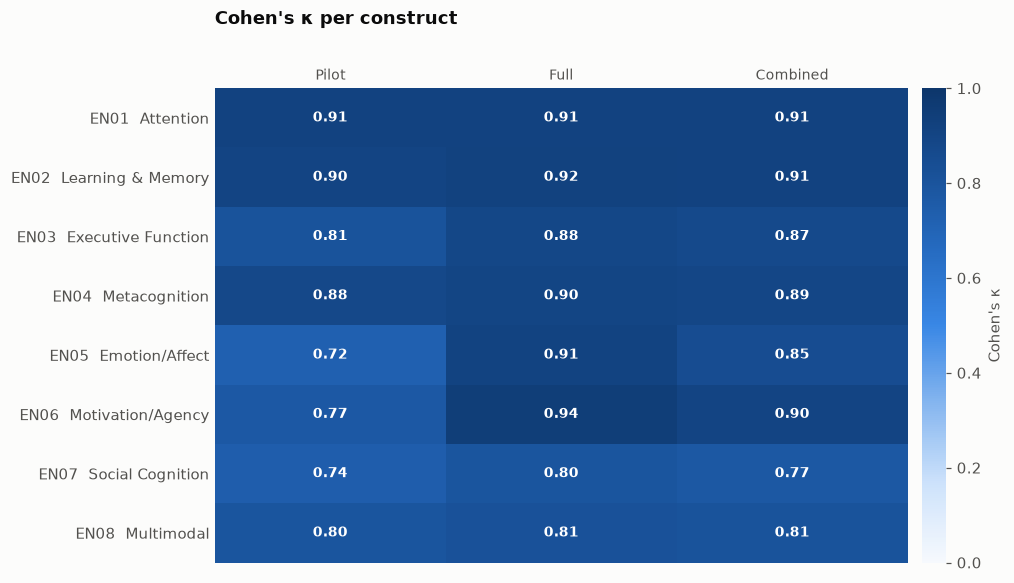

In [9]:
columns = [("pilot", "Pilot"), ("full", "Full"), ("combined", "Combined")]
columns = [(key, label) for key, label in columns if key in KAPPA]
matrix = np.array([[KAPPA[key].loc[c, "kappa"] for key, _ in columns] for c in EN_COLS], dtype=float)

fig, ax = plt.subplots(figsize=(8.6, 5.6))
im = ax.imshow(np.clip(matrix, 0, 1), cmap=SEQ_BLUE, vmin=0, vmax=1, aspect="auto")
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        v = matrix[i, j]
        ax.text(j, i, "–" if np.isnan(v) else f"{v:.2f}", ha="center", va="center", fontsize=9,
                color=cell_text_color(max(v, 0), 1), fontweight="bold" if v >= KAPPA_GATE else "normal")
ax.set_xticks(range(len(columns)), [label for _, label in columns], fontsize=9)
ax.set_yticks(range(len(EN_COLS)), [f"{c}  {EN_NAMES[c]}" for c in EN_COLS])
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
ax.xaxis.tick_top()
cbar = fig.colorbar(im, ax=ax, fraction=0.035, pad=0.02)
cbar.set_label("Cohen's κ", color=VIZ["muted"])
cbar.outline.set_visible(False)
ax.set_title("Cohen's κ per construct", pad=42)
save_fig(fig, "01_kappa_heatmap.png")

### Chart: positive labels per annotator

Each line joins the number of sentences that annotator A and annotator B labelled as positive for a construct. The ratio on the right shows how many times more positives B gave. Long lines mean a systematic difference in threshold rather than random disagreement.

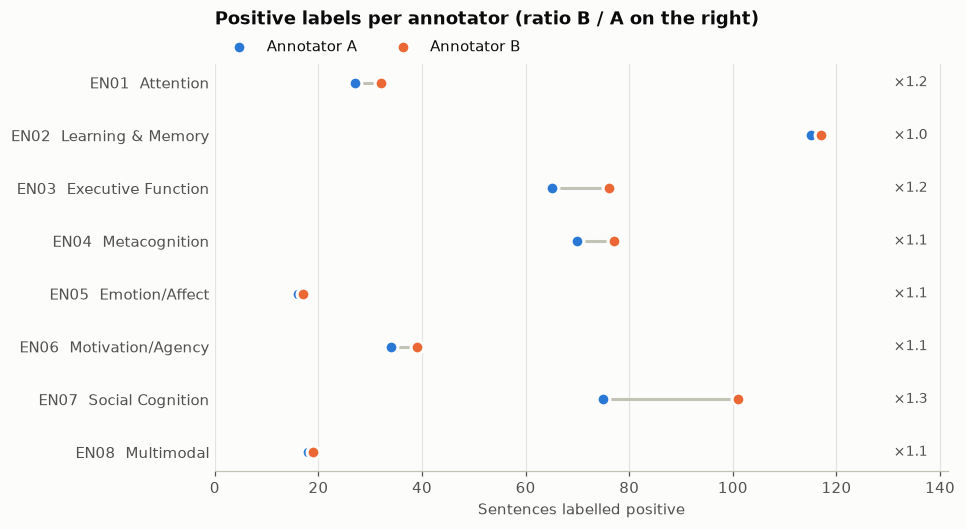

In [10]:
table = KAPPA.get("combined", next(iter(KAPPA.values())))
y = np.arange(len(EN_COLS))[::-1]
a_pos, b_pos = table["A=1"].to_numpy(), table["B=1"].to_numpy()

fig, ax = plt.subplots(figsize=(8.6, 4.8))
ax.hlines(y, np.minimum(a_pos, b_pos), np.maximum(a_pos, b_pos), color=VIZ["rule"], linewidth=2, zorder=1)
ax.scatter(a_pos, y, s=70, color=VIZ["blue"], edgecolor=VIZ["surface"], linewidth=2, zorder=2, label="Annotator A")
ax.scatter(b_pos, y, s=70, color=VIZ["orange"], edgecolor=VIZ["surface"], linewidth=2, zorder=2, label="Annotator B")
x_end = max(a_pos.max(), b_pos.max()) * 1.12
for yi, a, b in zip(y, a_pos, b_pos):
    ax.text(x_end, yi, f"×{b / a:.1f}" if a else "–", va="center", ha="left", fontsize=9, color=VIZ["muted"])
ax.set_yticks(y, [f"{c}  {EN_NAMES[c]}" for c in EN_COLS])
ax.set_xlim(0, x_end * 1.08)
ax.set_xlabel("Sentences labelled positive")
ax.grid(axis="x", color=VIZ["grid"], linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)
ax.spines["left"].set_visible(False)
# legend above the plot so it never covers the ratio labels
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, borderaxespad=0.2)
ax.set_title(pad=26, label="Positive labels per annotator (ratio B / A on the right)")
save_fig(fig, "02_annotator_dumbbell.png")

---
## 6. Gold standard

The gold standard is built from the labels of both annotators (`annotation/pilot_annotator_A/B.xlsx`, `full_annotator_A/B.xlsx`). Where the two annotators differ for a construct, the **conservative** rule applies: the label is 1 only when both have 1.

The number of positive examples per construct determines whether a classifier can learn it. Constructs with fewer than 20 positives are flagged as insufficient, and constructs with fewer than 100 as below the target size.

In [11]:
def resolve(a, b):
    """Labels equal for both annotators are kept; differences take the conservative rule (0)."""
    return {c: a[c] if a[c] == b[c] else 0 for c in EN_COLS}

gold, n_conservative = [], 0
for part, d in ann.items():
    for sid in d["common"]:
        a, b = d["A"][sid], d["B"][sid]
        n_conservative += sum(a[c] != b[c] for c in EN_COLS)
        s = corpus_by_id[sid]
        gold.append({k: s[k] for k in ["sent_id", "document_id", "document_type", "phase", "chapter", "text"]}
                    | resolve(a, b) | {"source": part})

path_gold = os.path.join(FOLDER["annotation"], "gold_standard.json")
save_json(gold, path_gold)

def gold_status(n):
    if n < 20: return "insufficient (<20)"
    if n < 100: return "below target (<100)"
    return "OK"

GOLD_POS = {c: sum(r[c] for r in gold) for c in EN_COLS}
display(pd.DataFrame([{"construct": c, "name": EN_NAMES[c], "positives": GOLD_POS[c],
                       "%": round(100 * GOLD_POS[c] / len(gold), 1), "status": gold_status(GOLD_POS[c])}
                      for c in EN_COLS]).set_index("construct"))
all_zero = sum(all(r[c] == 0 for c in EN_COLS) for r in gold)
print(f"Sentences: {len(gold)} | labels differing between annotators (conservative rule): "
      f"{n_conservative} | no construct: {all_zero} ({100 * all_zero / len(gold):.1f}%)")

,name,positives,%,status
construct,,,,
EN01,Attention,27,2.9,below target (<100)
EN02,Learning & Memory,107,11.6,OK
EN03,Executive Function,62,6.7,below target (<100)
EN04,Metacognition,66,7.2,below target (<100)
EN05,Emotion/Affect,14,1.5,insufficient (<20)
EN06,Motivation/Agency,33,3.6,below target (<100)
EN07,Social Cognition,70,7.6,below target (<100)
EN08,Multimodal,15,1.6,insufficient (<20)


Sentences: 919 | labels differing between annotators (conservative rule): 110 | no construct: 681 (74.1%)


### Chart: distinctive words per EN construct (gold standard)

One cloud per construct, built from the gold-standard sentences labelled with that construct. Word size is how **distinctive** the word is for the construct compared with all other gold sentences (log-odds ratio with an informative prior, z-score), not raw frequency, so words common to every curriculum sentence do not dominate. Indonesian stopwords and generic words (peserta, didik, murid, …) are removed; a word must occur at least twice. Topic words (e.g. *virus*, *evolusi*) can appear when a construct's positive sentences come mostly from one teaching module. EN05 and EN08 rest on few sentences (see the counts in the panel titles).

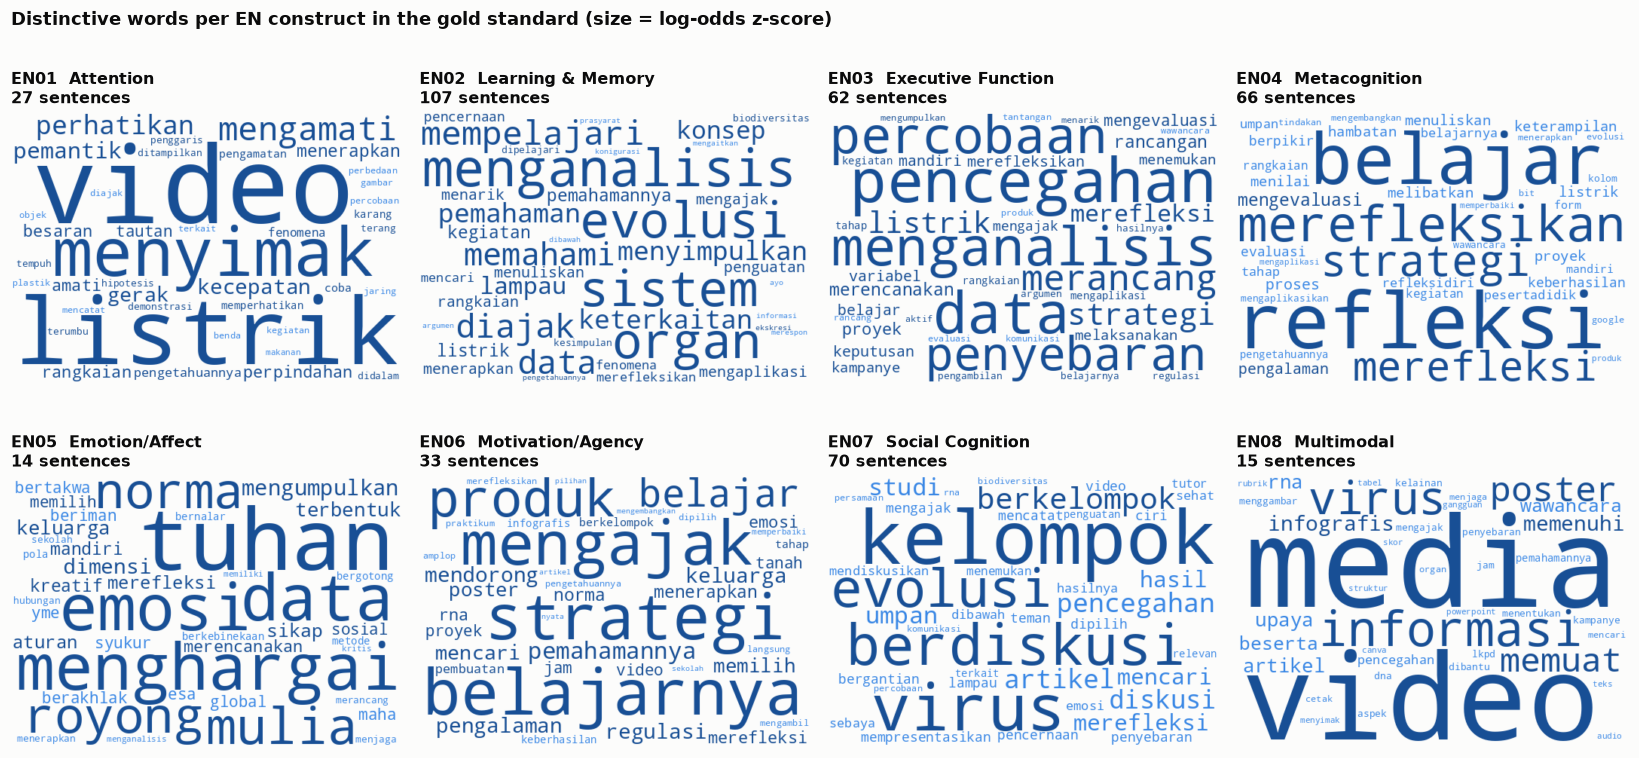

In [12]:
import math
from nltk.corpus import stopwords
from wordcloud import WordCloud

nltk.download("stopwords", quiet=True)
CLOUD_STOP = set(stopwords.words("indonesian")) | {
    "peserta", "didik", "murid", "siswa", "kalian", "kamu", "guru", "pendidik", "dapat", "secara", "melalui",
    "tersebut", "yaitu", "contoh", "hal", "berikut"}


def cloud_tokens(text):
    return [w for w in re.findall(r"[a-zA-Z]+", text.lower()) if len(w) >= 3 and w not in CLOUD_STOP]


def distinctive_words(target, rest, min_count=2, prior=0.05):
    """z-scored log-odds ratio with an informative prior (Monroe et al., 2008); positive scores only."""
    ct = Counter(w for t in target for w in cloud_tokens(t))
    co = Counter(w for t in rest for w in cloud_tokens(t))
    both = ct + co
    alpha = {w: prior * both[w] + 0.01 for w in both}
    n1, n2, a0 = sum(ct.values()), sum(co.values()), sum(alpha.values())
    scores = {}
    for w, c in ct.items():
        if c < min_count:
            continue
        delta = (math.log((c + alpha[w]) / (n1 + a0 - c - alpha[w]))
                 - math.log((co[w] + alpha[w]) / (n2 + a0 - co[w] - alpha[w])))
        z = delta / math.sqrt(1 / (c + alpha[w]) + 1 / (co[w] + alpha[w]))
        if z > 0:
            scores[w] = z
    return dict(sorted(scores.items(), key=lambda kv: -kv[1])[:40])


fig, axes = plt.subplots(2, 4, figsize=(15, 7.6))
for ax, c in zip(axes.flat, EN_COLS):
    target = [r["text"] for r in gold if r[c] == 1]
    rest = [r["text"] for r in gold if r[c] == 0]
    words = distinctive_words(target, rest)
    ax.set_title(f"{c}  {EN_NAMES[c]}\n{len(target)} sentences", fontsize=10.5)
    ax.axis("off")
    if not words:
        ax.text(0.5, 0.5, "too few sentences", ha="center", va="center", color=VIZ["muted"])
        continue
    top = max(words.values())
    cloud = WordCloud(width=520, height=360, background_color=VIZ["surface"], prefer_horizontal=1.0, random_state=SEED,
                      relative_scaling=0.7, min_font_size=8, margin=4,
                      color_func=lambda word, **kw: "#184f95" if words[word] >= 0.5 * top else "#3987e5")
    ax.imshow(cloud.generate_from_frequencies(words), interpolation="bilinear")
fig.suptitle("Distinctive words per EN construct in the gold standard (size = log-odds z-score)",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save_fig(fig, "02b_construct_wordclouds.png")

---
## 7. Multi-label classifier (IndoBERT)

```
gold standard ──► train 70% │ validation 15% │ test 15%   (stratified on the rarest positive construct)
                               │                 │
                               ├─ epoch selection│
                               └─ thresholds     └─ final evaluation (used once)
```

**Model.** `indobenchmark/indobert-base-p2` with a linear head of eight outputs on the `[CLS]` representation. Each output is an independent probability (sigmoid), trained with binary cross-entropy.

**Design choices**
| Choice | Rationale |
|---|---|
| Separate validation and test sets | Model selection and threshold tuning use validation data only, so the test score is not optimistically biased |
| `max_length = 128`, dynamic padding | 99% of corpus sentences are ≤ 116 tokens; padding to 512 exceeds the memory of a 4 GB GPU |
| `pos_weight` = negatives / positives (capped at 10) | Counteracts the strong class imbalance of the rarer constructs |
| Threshold tuned per construct on validation data | A single 0.5 threshold is not optimal for imbalanced labels |
| FP32 training | Mixed precision is slower on GPUs without tensor cores (e.g., GTX 16xx) |

Scores for constructs with fewer than five positives in the test set are reported but marked as not estimable.

In [13]:
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModel, get_linear_schedule_with_warmup
from transformers.utils import logging as hf_logging
from huggingface_hub.utils import logging as hub_logging
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
hub_logging.set_verbosity_error()

MODEL_NAME = "indobenchmark/indobert-base-p2"
HP = {"max_length": 128, "batch_size": 16, "epochs": 8, "learning_rate": 2e-5,
      "warmup_ratio": 0.1, "max_pos_weight": 10.0}
PATH_MODEL     = os.path.join(FOLDER["model"], "best_model.pt")
PATH_MODEL_CFG = os.path.join(FOLDER["model"], "model_config.json")

class IndoBERTMultiLabel(torch.nn.Module):
    """IndoBERT encoder + dropout + linear head with one logit per construct."""
    def __init__(self, model_name, num_labels):
        super().__init__()
        self.bert = AutoModel.from_pretrained(model_name)
        self.dropout = torch.nn.Dropout(0.1)
        self.classifier = torch.nn.Linear(self.bert.config.hidden_size, num_labels)

    def forward(self, input_ids, attention_mask):
        out = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        return self.classifier(self.dropout(out.last_hidden_state[:, 0, :]))  # [CLS]

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def encode(texts):
    return tokenizer(texts, max_length=HP["max_length"], padding=True, truncation=True, return_tensors="pt")

def make_batch(records):
    enc = encode([r["text"] for r in records])
    labels = torch.tensor([[float(r[c]) for c in EN_COLS] for r in records])
    return enc["input_ids"], enc["attention_mask"], labels

@torch.no_grad()
def predict_proba(model, texts, batch_size=64):
    """Probabilities of shape (n, 8). Texts are batched by length to minimise padding."""
    model.eval()
    order = np.argsort([len(t) for t in texts])
    probs = np.zeros((len(texts), len(EN_COLS)), dtype=np.float32)
    for i in range(0, len(texts), batch_size):
        idx = order[i:i + batch_size]
        enc = encode([texts[j] for j in idx]).to(DEVICE)
        probs[idx] = torch.sigmoid(model(enc["input_ids"], enc["attention_mask"])).cpu().numpy()
    return probs

def label_matrix(records):
    return np.array([[r[c] for c in EN_COLS] for r in records], dtype=int)

def load_trained_model():
    cfg = load_json(PATH_MODEL_CFG)
    m = IndoBERTMultiLabel(cfg["model_name"], len(EN_COLS)).to(DEVICE)
    m.load_state_dict(torch.load(PATH_MODEL, map_location=DEVICE, weights_only=True))
    m.eval()
    return m, np.array([cfg["thresholds"][c] for c in EN_COLS])

print(f"{MODEL_NAME} | device: {DEVICE} | {HP}")

indobenchmark/indobert-base-p2 | device: cuda | {'max_length': 128, 'batch_size': 16, 'epochs': 8, 'learning_rate': 2e-05, 'warmup_ratio': 0.1, 'max_pos_weight': 10.0}


In [14]:
# Stratification key: the rarest positive construct of each sentence ("none" if all are 0).
set_seed()
keys = []
for r in gold:
    pos = [c for c in EN_COLS if r[c] == 1]
    keys.append(min(pos, key=GOLD_POS.get) if pos else "none")
counts = Counter(keys)
keys = [k if counts[k] >= 10 else "rare" for k in keys]
if Counter(keys)["rare"] < 10:
    keys = ["none" if k == "rare" else k for k in keys]

idx = np.arange(len(gold))
tr_idx, tmp_idx = train_test_split(idx, test_size=0.30, random_state=SEED, stratify=keys)
try:
    va_idx, te_idx = train_test_split(tmp_idx, test_size=0.50, random_state=SEED,
                                      stratify=[keys[i] for i in tmp_idx])
except ValueError:
    va_idx, te_idx = train_test_split(tmp_idx, test_size=0.50, random_state=SEED)

train_recs = [gold[i] for i in tr_idx]
val_recs   = [gold[i] for i in va_idx]
test_recs  = [gold[i] for i in te_idx]
y_tr, y_va, y_te = label_matrix(train_recs), label_matrix(val_recs), label_matrix(test_recs)

print("Positive examples per construct and split")
display(pd.DataFrame({"train": y_tr.sum(0), "val": y_va.sum(0), "test": y_te.sum(0)}, index=EN_COLS)
        .T.assign(n=[len(train_recs), len(val_recs), len(test_recs)]))

Positive examples per construct and split


,EN01,EN02,EN03,EN04,EN05,EN06,EN07,EN08,n
train,18,69,41,47,10,22,52,11,643
val,4,21,9,10,2,6,11,2,138
test,5,17,12,9,2,5,7,2,138


In [15]:
set_seed()
pos = y_tr.sum(0); neg = len(y_tr) - pos
pos_weight = np.clip(np.where(pos > 0, neg / np.maximum(pos, 1), 1.0), 1.0, HP["max_pos_weight"])
loss_fn = torch.nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pos_weight, dtype=torch.float, device=DEVICE))
print("pos_weight:", {c: round(float(w), 1) for c, w in zip(EN_COLS, pos_weight)})

model = IndoBERTMultiLabel(MODEL_NAME, len(EN_COLS)).to(DEVICE)
optimizer = torch.optim.AdamW(model.parameters(), lr=HP["learning_rate"])
train_loader = DataLoader(train_recs, batch_size=HP["batch_size"], shuffle=True, collate_fn=make_batch,
                          generator=torch.Generator().manual_seed(SEED))
total_steps = len(train_loader) * HP["epochs"]
scheduler = get_linear_schedule_with_warmup(optimizer, int(total_steps * HP["warmup_ratio"]), total_steps)

val_texts = [r["text"] for r in val_recs]
history, best = [], {"f1": -1.0}
t0 = datetime.now()
for epoch in range(1, HP["epochs"] + 1):
    model.train()
    total_loss = 0.0
    for input_ids, attention_mask, labels in train_loader:
        optimizer.zero_grad()
        loss = loss_fn(model(input_ids.to(DEVICE), attention_mask.to(DEVICE)), labels.to(DEVICE))
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step(); scheduler.step()
        total_loss += loss.item()
    f1_val = f1_score(y_va, predict_proba(model, val_texts) >= 0.5, average="macro", zero_division=0)
    history.append({"epoch": epoch, "loss": round(total_loss / len(train_loader), 4), "val_macro_f1": round(f1_val, 4)})
    mark = ""
    if f1_val > best["f1"]:
        best = {"f1": f1_val, "epoch": epoch,
                "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}
        mark = "  *"
    print(f"  epoch {epoch} | loss {history[-1]['loss']:.4f} | val macro-F1 {f1_val:.4f}{mark}")

model.load_state_dict(best["state"])
print(f"Selected epoch: {best['epoch']} (val macro-F1 {best['f1']:.4f}) | {datetime.now() - t0}")

pos_weight: {'EN01': 10.0, 'EN02': 8.3, 'EN03': 10.0, 'EN04': 10.0, 'EN05': 10.0, 'EN06': 10.0, 'EN07': 10.0, 'EN08': 10.0}
  epoch 1 | loss 0.8580 | val macro-F1 0.2787  *
  epoch 2 | loss 0.4848 | val macro-F1 0.4692  *
  epoch 3 | loss 0.2789 | val macro-F1 0.4864  *
  epoch 4 | loss 0.1788 | val macro-F1 0.5104  *
  epoch 5 | loss 0.1149 | val macro-F1 0.4995
  epoch 6 | loss 0.0770 | val macro-F1 0.5381  *
  epoch 7 | loss 0.0584 | val macro-F1 0.5346
  epoch 8 | loss 0.0475 | val macro-F1 0.5514  *
Selected epoch: 8 (val macro-F1 0.5514) | 0:03:04.571174


In [16]:
def tune_thresholds(y, p, grid=np.round(np.arange(0.05, 0.96, 0.05), 2)):
    """Per construct, the threshold with the highest validation F1 (0.5 when no positive can be recovered)."""
    th = {}
    for j, c in enumerate(EN_COLS):
        scores = [f1_score(y[:, j], p[:, j] >= t, zero_division=0) for t in grid]
        th[c] = float(grid[int(np.argmax(scores))]) if y[:, j].sum() > 0 and max(scores) > 0 else 0.5
    return th

thresholds = tune_thresholds(y_va, predict_proba(model, val_texts))
TH = np.array([thresholds[c] for c in EN_COLS])

p_te = predict_proba(model, [r["text"] for r in test_recs])
pred_te = (p_te >= TH).astype(int)
prec, rec, f1s, support = precision_recall_fscore_support(y_te, pred_te, average=None, zero_division=0)
MIN_TEST_POS = 5
report = pd.DataFrame({"name": [EN_NAMES[c] for c in EN_COLS], "gold_pos": [GOLD_POS[c] for c in EN_COLS],
                       "threshold": TH, "precision": prec.round(3), "recall": rec.round(3), "f1": f1s.round(3),
                       "test_pos": support, "estimable": support >= MIN_TEST_POS}, index=EN_COLS)
print("Test set evaluation")
display(report)
macro_all = float(f1s.mean())
macro_est = float(f1s[support >= MIN_TEST_POS].mean()) if (support >= MIN_TEST_POS).any() else float("nan")
print(f"macro-F1 (all constructs)           : {macro_all:.3f}")
print(f"macro-F1 (estimable, ≥ 5 test positives): {macro_est:.3f}")

torch.save(model.state_dict(), PATH_MODEL)
save_json({"model_name": MODEL_NAME, "hyperparameters": HP, "thresholds": thresholds,
           "best_epoch": best["epoch"], "val_macro_f1": round(best["f1"], 4),
           "test_macro_f1_all": round(macro_all, 4), "test_macro_f1_estimable": round(macro_est, 4),
           "split_sizes": {"train": len(train_recs), "val": len(val_recs), "test": len(test_recs)},
           "trained_at": datetime.now().isoformat(timespec="seconds")}, PATH_MODEL_CFG)
save_json({"history": history, "test_report": report.reset_index(names="construct").to_dict("records")},
          os.path.join(FOLDER["results"], "training_report.json"))
print(f"{PATH_MODEL}, {PATH_MODEL_CFG}, {os.path.join(FOLDER['results'], 'training_report.json')}")

Test set evaluation


,name,gold_pos,threshold,precision,recall,f1,test_pos,estimable
EN01,Attention,27,0.25,0.500,0.400,0.444,5,True
EN02,Learning & Memory,107,0.20,0.480,0.706,0.571,17,True
EN03,Executive Function,62,0.80,0.833,0.417,0.556,12,True
EN04,Metacognition,66,0.55,0.400,0.222,0.286,9,True
EN05,Emotion/Affect,14,0.50,1.000,0.500,0.667,2,False
EN06,Motivation/Agency,33,0.45,0.000,0.000,0.000,5,True
EN07,Social Cognition,70,0.85,0.571,0.571,0.571,7,True
EN08,Multimodal,15,0.25,0.000,0.000,0.000,2,False


macro-F1 (all constructs)           : 0.387
macro-F1 (estimable, ≥ 5 test positives): 0.405
model/best_model.pt, model/model_config.json, results/training_report.json


### Chart: test F1 vs number of positive examples

Each point is a construct. Constructs with few positive examples in the gold standard reach a low F1; hollow points have fewer than five positives in the test set, so their F1 is not a reliable estimate.

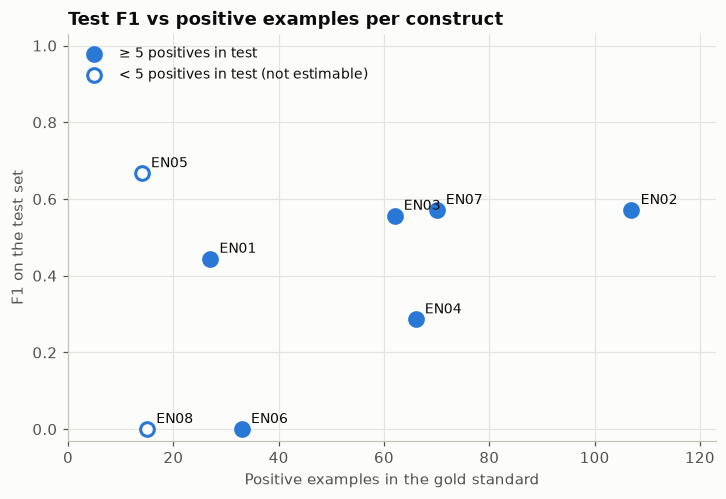

In [17]:
fig, ax = plt.subplots(figsize=(7.6, 4.8))
for est, face in [(True, VIZ["blue"]), (False, VIZ["surface"])]:
    part = report[report["estimable"] == est]
    ax.scatter(part["gold_pos"], part["f1"], s=80, facecolor=face, edgecolor=VIZ["blue"], linewidth=2, zorder=2,
               label="≥ 5 positives in test" if est else "< 5 positives in test (not estimable)")
for code_en, row in report.iterrows():
    ax.annotate(code_en, (row["gold_pos"], row["f1"]), xytext=(6, 4), textcoords="offset points", fontsize=9, color=VIZ["ink"])
ax.set_xlim(0, report["gold_pos"].max() * 1.15)
ax.set_ylim(-0.03, 1.03)
ax.set_xlabel("Positive examples in the gold standard")
ax.set_ylabel("F1 on the test set")
ax.grid(color=VIZ["grid"], linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(loc="upper left", frameon=False, fontsize=9)
ax.set_title("Test F1 vs positive examples per construct")
save_fig(fig, "03_f1_vs_positives.png")

### 7b. Cross-validation and learning curve

The test set of §7 holds only 138 sentences (2–17 positives per construct), so the test F1 depends heavily on chance: its 95% confidence interval is about ±0.12. To estimate performance more stably, and to see whether more data would help, additional analyses were run with `scripts/eksperimen_f1.py` (about six GPU hours; the results are read here, not recomputed):

- **5-fold cross-validation** on train + validation (781 sentences): every sentence is predicted exactly once by a model that did not see it in training; thresholds are tuned on the other folds.
- **IndoBERT + DAPT**: IndoBERT first continues pre-training (masked language modelling) on the unlabelled corpus sentences, test sentences excluded, and is then fine-tuned as in §7.
- **Learning curve**: both IndoBERT + DAPT and a TF-IDF + logistic regression baseline are retrained on 25, 50, 75, and 100% of the training part of each fold.

Each model was chosen on cross-validation before the test set was opened, and the test set was opened once per model. Other attempts (frozen embeddings, focal loss, ensembles, merging EN05 and EN06) are described in `docs/eksperimen_f1.md`. The §7 model is kept for §8–§13, because the advantage of DAPT in cross-validation was not confirmed on the test set.

F1 per construct in 5-fold cross-validation (train + validation, 781 sentences), plus macro-F1 on the test set


,EN01,EN02,EN03,EN04,EN05,EN06,EN07,EN08,macro (CV),macro (test)
IndoBERT (§7 setting),0.426,0.551,0.589,0.679,0.4,0.370,0.716,0.609,0.542,0.380
IndoBERT + DAPT,0.683,0.575,0.613,0.667,0.5,0.384,0.754,0.476,0.581,0.378


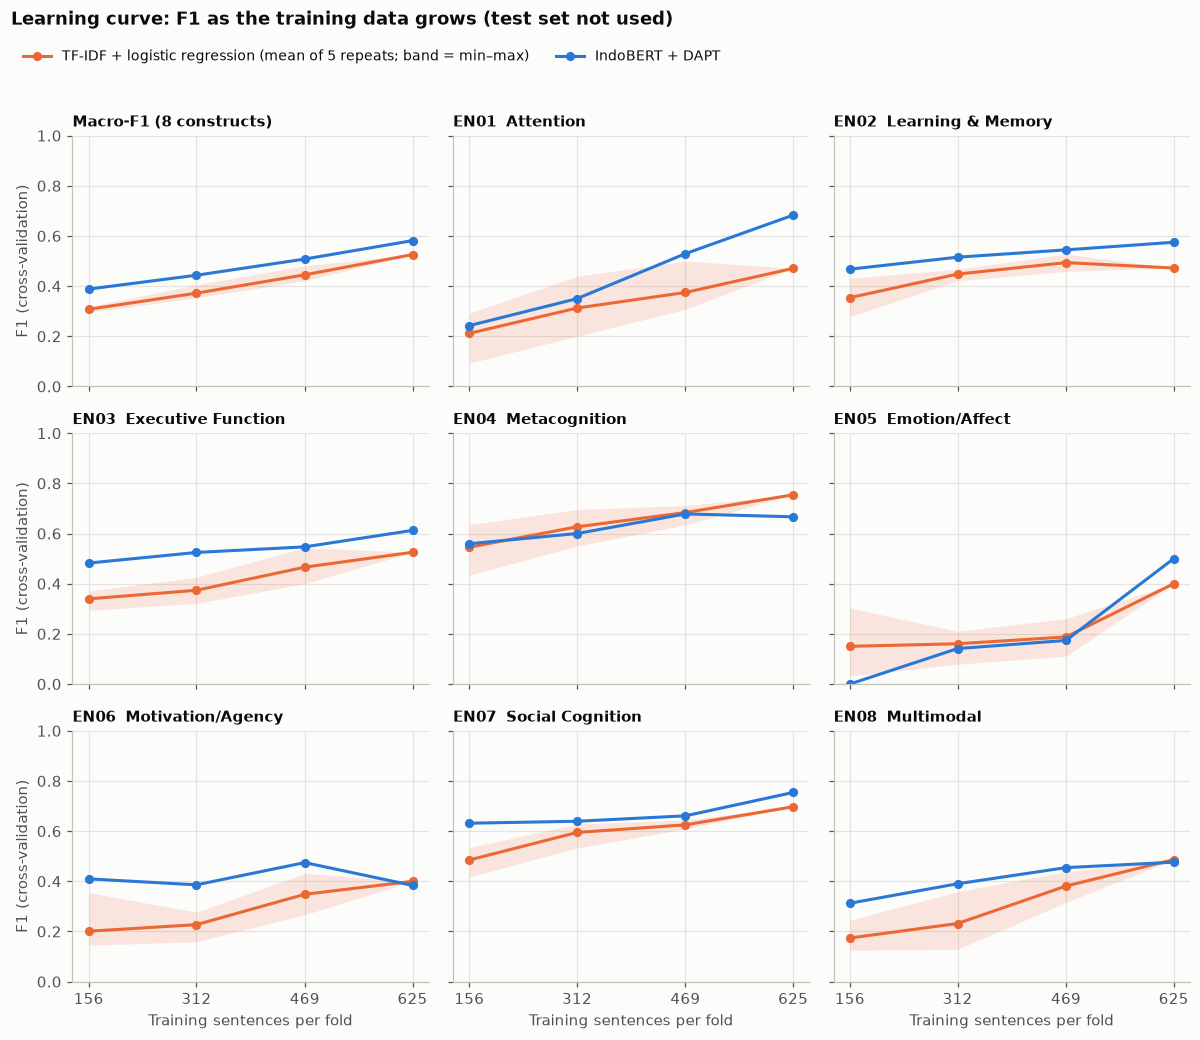

In [18]:
EXP_DIR = os.path.join(FOLDER["results"], "eksperimen_f1")
cv = {}
for name, label in [("ft_base_e8", "IndoBERT (§7 setting)"), ("ft_dapt_e8", "IndoBERT + DAPT")]:
    r = load_json(os.path.join(EXP_DIR, f"final_{name}.json"))
    cv[label] = {**r["cv_dev_f1"], "macro (CV)": r["cv_dev_macro_f1"], "macro (test)": r["test_macro_f1"]}
print("F1 per construct in 5-fold cross-validation (train + validation, 781 sentences), plus macro-F1 on the test set")
display(pd.DataFrame(cv).T.round(3))

curve = load_json(os.path.join(EXP_DIR, "kurva_belajar.json"))
fr = ["0.25", "0.5", "0.75", "1.0"]
x = [curve["n_train"][f] for f in fr]
fig, axes = plt.subplots(3, 3, figsize=(11, 9.6), sharex=True, sharey=True)
panels = [("macro", "Macro-F1 (8 constructs)")] + [(c, f"{c}  {EN_NAMES[c]}") for c in EN_COLS]
for ax, (key, title) in zip(axes.flat, panels):
    j = None if key == "macro" else EN_COLS.index(key)
    pick = lambda v: np.mean(v, axis=-1) if j is None else np.asarray(v)[..., j]
    tf = np.array([pick(curve["tfidf"][f]) for f in fr])           # (fraction, repeat)
    bert = np.array([pick(curve["dapt"][f]["f1"]) for f in fr])
    ax.fill_between(x, tf.min(1), tf.max(1), color=VIZ["orange"], alpha=0.15, linewidth=0)
    ax.plot(x, tf.mean(1), color=VIZ["orange"], linewidth=2, marker="o", markersize=5,
            label="TF-IDF + logistic regression (mean of 5 repeats; band = min–max)")
    ax.plot(x, bert, color=VIZ["blue"], linewidth=2, marker="o", markersize=5, label="IndoBERT + DAPT")
    ax.set_title(title, fontsize=10)
    ax.set_ylim(0, 1)
    ax.grid(color=VIZ["grid"], linewidth=0.8)
    ax.set_axisbelow(True)
for ax in axes[-1]:
    ax.set_xticks(x)
    ax.set_xlabel("Training sentences per fold")
for ax in axes[:, 0]:
    ax.set_ylabel("F1 (cross-validation)")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper left", bbox_to_anchor=(0.01, 0.955), ncol=2, frameon=False, fontsize=9)
fig.suptitle("Learning curve: F1 as the training data grows (test set not used)",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout(rect=(0, 0, 1, 0.93))
save_fig(fig, "03b_learning_curve.png")

---
## 8. EN labelling of the corpus

The classifier labels every corpus sentence, including the annotated ones and the OCR-derived CP sentences, so that all documents and layers are measured with the same instrument. Labels and probabilities are written to `results/corpus_en_predictions.json`; the corpus files are not modified.

The validity of these labels is bounded by the inter-rater agreement (§5) and the classifier performance (§7).

In [19]:
if "model" not in globals() or "TH" not in globals():
    model, TH = load_trained_model()

t0 = datetime.now()
probs = predict_proba(model, [r["text"] for r in corpus])
for r, p in zip(corpus, probs):
    for j, c in enumerate(EN_COLS):
        r[c] = int(p[j] >= TH[j])
        r[c + "_prob"] = round(float(p[j]), 3)

save_json([{k: r[k] for k in ["sent_id"] + EN_COLS + [c + "_prob" for c in EN_COLS]} for r in corpus],
          os.path.join(FOLDER["results"], "corpus_en_predictions.json"))
print(f"{len(corpus)} sentences labelled ({datetime.now() - t0})")
display(pd.DataFrame({"name": [EN_NAMES[c] for c in EN_COLS],
                      "n": [sum(r[c] for r in corpus) for c in EN_COLS],
                      "%": [round(100 * sum(r[c] for r in corpus) / len(corpus), 2) for c in EN_COLS]},
                     index=EN_COLS))

13146 sentences labelled (0:01:28.497602)


,name,n,%
EN01,Attention,518,3.94
EN02,Learning & Memory,1627,12.38
EN03,Executive Function,158,1.20
EN04,Metacognition,262,1.99
EN05,Emotion/Affect,37,0.28
EN06,Motivation/Agency,139,1.06
EN07,Social Cognition,325,2.47
EN08,Multimodal,94,0.72


### Chart: co-occurrence of EN constructs (exploratory)

Number of corpus sentences that the model labelled with both constructs; the diagonal is the number of sentences with that construct. Because the labels come from the classifier in §7, read this as exploratory.

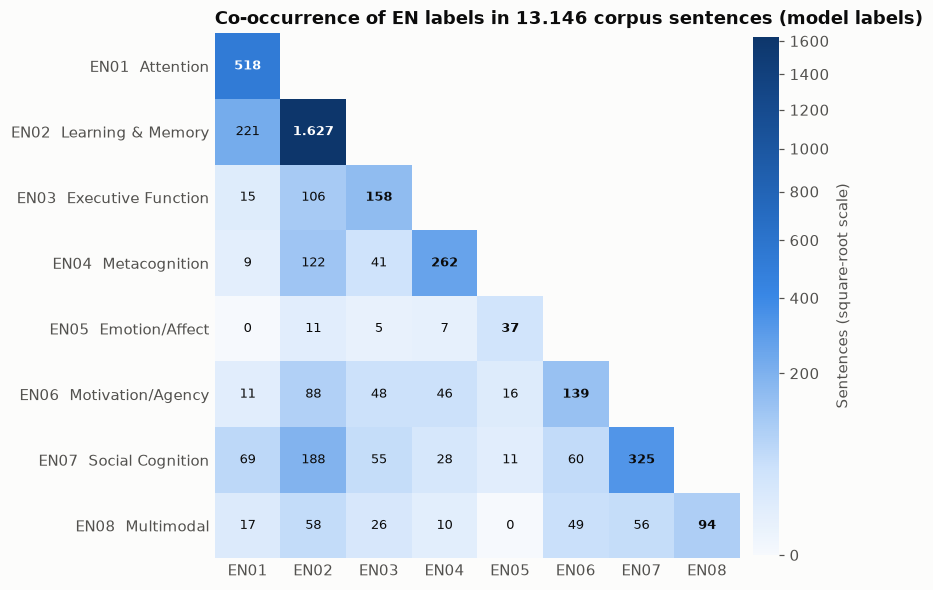

In [20]:
labels = np.array([[r[c] for c in EN_COLS] for r in corpus])
cooc = labels.T @ labels
mask = np.triu(np.ones_like(cooc, dtype=bool), k=1)
shown = np.ma.masked_where(mask, cooc)

fig, ax = plt.subplots(figsize=(7.6, 6.2))
norm = PowerNorm(gamma=0.5, vmin=0, vmax=max(1, cooc.max()))
im = ax.imshow(shown, cmap=SEQ_BLUE, norm=norm)
for i in range(len(EN_COLS)):
    for j in range(i + 1):
        ax.text(j, i, f"{cooc[i, j]:,}".replace(",", "."), ha="center", va="center", fontsize=8.5,
                color="white" if norm(cooc[i, j]) >= 0.55 else VIZ["ink"],
                fontweight="bold" if i == j else "normal")
ax.set_xticks(range(len(EN_COLS)), EN_COLS)
ax.set_yticks(range(len(EN_COLS)), [f"{c}  {EN_NAMES[c]}" for c in EN_COLS])
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
cbar = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cbar.set_label("Sentences (square-root scale)", color=VIZ["muted"])
cbar.outline.set_visible(False)
ax.set_title(f"Co-occurrence of EN labels in {len(corpus):,} corpus sentences (model labels)".replace(",", "."))
save_fig(fig, "04_en_cooccurrence.png")

---
## 9. Biology concept extraction

Each Biology concept is defined by a list of synonyms (e.g., `pembelahan_sel` = *mitosis*, *meiosis*, *pembelahan sel*, *siklus sel*). A sentence mentions a concept when one of its synonyms occurs as a **whole word**, optionally followed by the Indonesian suffix *-nya*. Whole-word matching prevents false matches inside unrelated words (e.g., *sel* in *selalu*, *rna* in *alternatif*).

**Cognitive demand (Bloom).** Each sentence receives a heuristic Bloom level from the action verbs it contains: 3 = analyse/evaluate/create, 2 = explain/compare/classify, 1 = recall/identify, 0 = no Bloom verb. Verb roots are matched inside words to cover Indonesian affixation (*menganalisis*, *dianalisis*).

In [21]:
BIOLOGY_CONCEPTS = {
    "sel"            : ["sel", "seluler", "intraseluler", "unit kehidupan"],
    "membran_sel"    : ["membran sel", "membran plasma", "membran biologis"],
    "organel"        : ["organel", "mitokondria", "kloroplas", "ribosom", "lisosom", "vakuola", "nukleus"],
    "dna"            : ["dna", "deoksiribonukleat", "materi genetik"],
    "rna"            : ["rna", "ribonukleat", "mrna", "trna", "rrna"],
    "gen"            : ["gen", "alel", "lokus gen"],
    "kromosom"       : ["kromosom", "kromatid", "sentromer"],
    "protein"        : ["protein", "enzim", "polipeptida", "asam amino"],
    "metabolisme"    : ["metabolisme", "katabolisme", "anabolisme"],
    "fotosintesis"   : ["fotosintesis", "fotosintesa"],
    "respirasi"      : ["respirasi seluler", "glikolisis", "siklus krebs", "rantai transport elektron"],
    "pembelahan_sel" : ["mitosis", "meiosis", "pembelahan sel", "siklus sel"],
    "ekosistem"      : ["ekosistem", "lingkungan hidup", "habitat"],
    "evolusi"        : ["evolusi", "seleksi alam", "adaptasi"],
    "hereditas"      : ["hereditas", "pewarisan sifat", "genetika"],
    "ekspresi_gen"   : ["ekspresi gen", "transkripsi", "translasi"],
    "homeostasis"    : ["homeostasis", "regulasi fisiologis"],
    "sistem_organ"   : ["sistem organ", "jaringan", "organ tubuh"],
    "virus"          : ["virus", "virion", "patogen"],
    "bakteri"        : ["bakteri", "prokariota"],
    "jamur"          : ["jamur", "fungi", "miselium"],
    "keanekaragaman" : ["keanekaragaman hayati", "biodiversitas", "kehati", "konservasi"],
    "bioteknologi"   : ["bioteknologi", "rekombinasi dna", "fermentasi"],
    "perubahan_iklim": ["perubahan iklim", "pemanasan global", "gas rumah kaca"],
}

def concept_pattern(synonyms):
    alt = "|".join(re.escape(s) for s in sorted(synonyms, key=len, reverse=True))
    return re.compile(rf"(?<!\w)(?:{alt})(?:nya)?(?!\w)", re.IGNORECASE)

CONCEPT_RE = {cid: concept_pattern(syns) for cid, syns in BIOLOGY_CONCEPTS.items()}

BLOOM_VERBS = {
    3: ["analisis", "evaluasi", "rancang", "ciptakan", "mensintesis", "menyintesis", "kritis", "buktikan", "kembangkan"],
    2: ["jelaskan", "deskripsikan", "klasifikasikan", "bandingkan", "hubungkan", "ringkas"],
    1: ["ingat", "sebutkan", "identifikasi", "definisi", "kenali", "daftarkan"],
}
BLOOM_EXCLUDE = {"peringatan"}  # contains 'ingat' but is not a recall verb

def bloom_level(text):
    words = [w for w in re.findall(r"\w+", text.lower()) if w not in BLOOM_EXCLUDE]
    for level in (3, 2, 1):
        if any(root in w for w in words for root in BLOOM_VERBS[level]):
            return level
    return 0

for r in corpus:
    r["bloom"] = bloom_level(r["text"])

concept_occurrences = defaultdict(list)
for r in corpus:
    for cid, pat in CONCEPT_RE.items():
        if pat.search(r["text"]):
            concept_occurrences[cid].append({k: r[k] for k in ["sent_id", "document_id", "document_type",
                                                              "phase", "grade", "chapter", "page", "bloom"]}
                                            | {"text_snippet": r["text"][:150]})
save_json(dict(concept_occurrences), os.path.join(FOLDER["results"], "concept_occurrences.json"))

display(pd.DataFrame([{"concept": cid, "total": len(occ),
                       "CP": sum(o["document_type"] == "CP" for o in occ),
                       "module": sum(o["document_type"] == "module" for o in occ),
                       "BS": sum(o["document_type"] == "BS" for o in occ),
                       "phase_E": sum(o["phase"] == "E" for o in occ),
                       "phase_F": sum(o["phase"] == "F" for o in occ)}
                      for cid, occ in sorted(concept_occurrences.items(), key=lambda x: -len(x[1]))])
        .set_index("concept"))
print(os.path.join(FOLDER["results"], "concept_occurrences.json"))

,total,CP,module,BS,phase_E,phase_F
concept,,,,,,
sel,831,5,8,745,78,753
sistem_organ,424,6,52,270,56,367
protein,410,0,16,355,20,390
virus,319,1,30,277,216,103
dna,280,0,18,224,17,263
gen,271,0,12,247,18,253
bioteknologi,263,5,1,199,27,232
evolusi,225,5,34,166,13,211
perubahan_iklim,202,3,16,111,175,21


results/concept_occurrences.json


### Chart: Biology concepts per curriculum layer

One cloud per layer. The size of a concept is the number of the layer's sentences that mention it (§9 whole-word matching), so the clouds show which concepts each layer emphasises. Sizes are relative within a layer; the layers differ greatly in size (number of sentences in the title).

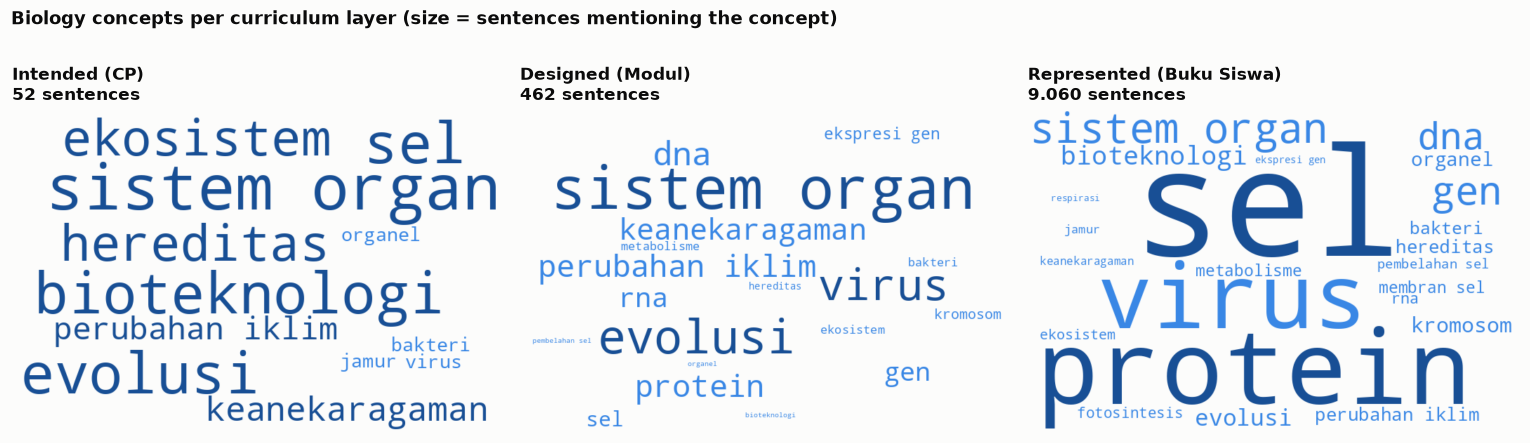

In [22]:
fig, axes = plt.subplots(1, len(LAYERS), figsize=(14, 4.6))
for ax, (dt, layer) in zip(axes, LAYERS.items()):
    freq = {cid.replace("_", " "): sum(o["document_type"] == dt for o in occ) for cid, occ in concept_occurrences.items()}
    freq = {k: v for k, v in freq.items() if v > 0}
    n_layer = sum(r["document_type"] == dt for r in corpus)
    ax.set_title(f"{layer}\n{n_layer:,} sentences".replace(",", "."), fontsize=11)
    ax.axis("off")
    if not freq:
        ax.text(0.5, 0.5, "no concepts found", ha="center", va="center", color=VIZ["muted"])
        continue
    top = max(freq.values())
    cloud = WordCloud(width=700, height=460, background_color=VIZ["surface"], prefer_horizontal=1.0, random_state=SEED,
                      relative_scaling=0.6, min_font_size=9, margin=6,
                      color_func=lambda word, **kw: "#184f95" if freq[word] >= 0.4 * top else "#3987e5")
    ax.imshow(cloud.generate_from_frequencies(freq), interpolation="bilinear")
fig.suptitle("Biology concepts per curriculum layer (size = sentences mentioning the concept)",
             x=0.01, ha="left", fontweight="bold", fontsize=12)
fig.tight_layout()
save_fig(fig, "05_concept_wordclouds.png")

### Chart: concept coverage per document

Rows are concepts (most frequent first); columns are documents grouped by phase (E, F, cross-phase). Colour is the share of the document's sentences that mention the concept, so long and short documents are comparable. A concept that is dark in Phase E and again in Phase F recurs across phases (CA01).

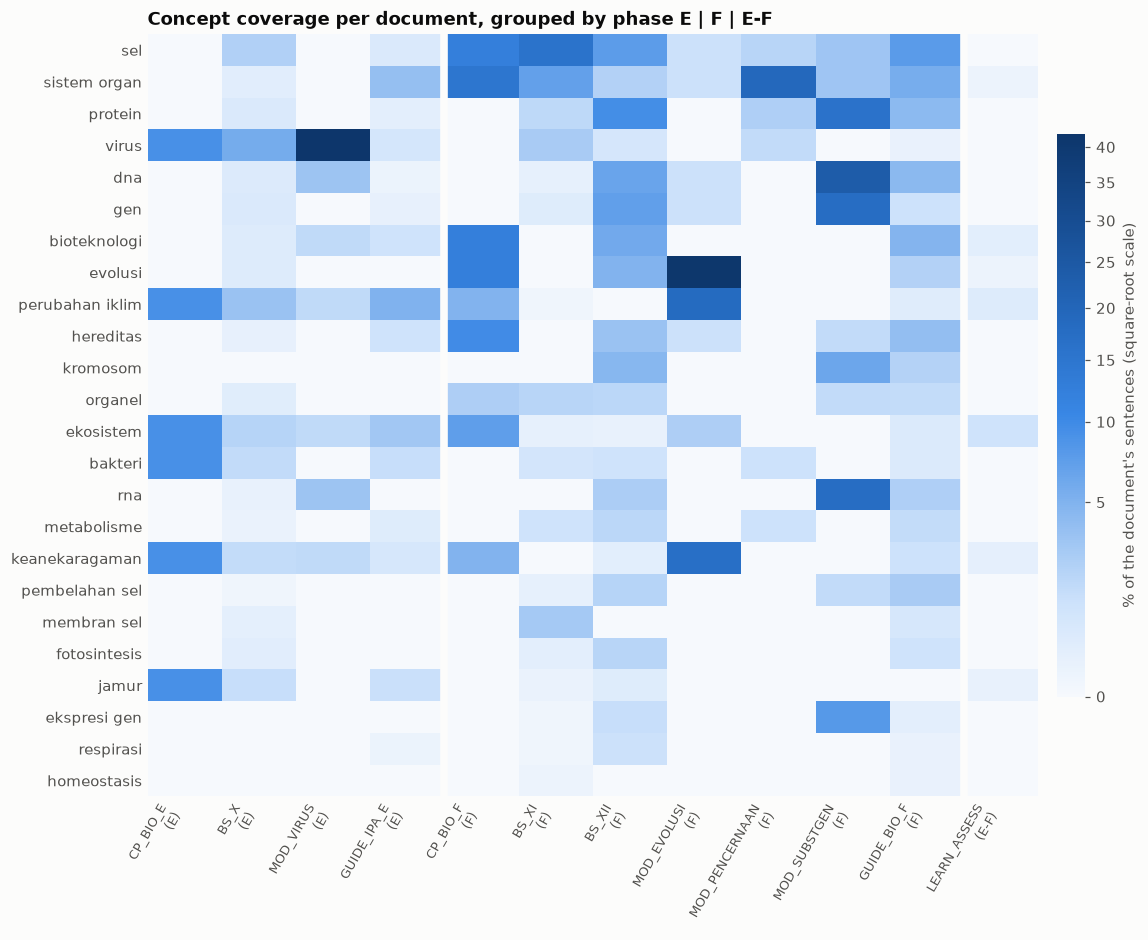

In [23]:
phase_order = {"E": 0, "F": 1, "E-F": 2}
type_order = {"CP": 0, "BS": 1, "module": 2, "guide": 3, "assess": 4}
doc_ids = sorted({r["document_id"] for r in corpus},
                 key=lambda d: (phase_order[DOC_META[d]["phase"]], type_order[DOC_META[d]["document_type"]], d))
n_doc = Counter(r["document_id"] for r in corpus)
concepts_sorted = sorted(concept_occurrences, key=lambda c: -len(concept_occurrences[c]))
share = np.array([[100 * sum(o["document_id"] == d for o in concept_occurrences[c]) / n_doc[d] for d in doc_ids]
                  for c in concepts_sorted])

fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(share, cmap=SEQ_BLUE, norm=PowerNorm(gamma=0.5, vmin=0, vmax=share.max()), aspect="auto")
ax.set_xticks(range(len(doc_ids)), [f"{d}\n({DOC_META[d]['phase']})" for d in doc_ids], rotation=60, ha="right", fontsize=8.5)
ax.set_yticks(range(len(concepts_sorted)), [c.replace("_", " ") for c in concepts_sorted])
ax.tick_params(length=0)
for side in ax.spines.values():
    side.set_visible(False)
for i in range(1, len(doc_ids)):
    if DOC_META[doc_ids[i]]["phase"] != DOC_META[doc_ids[i - 1]]["phase"]:
        ax.axvline(i - 0.5, color=VIZ["surface"], linewidth=5)
cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cbar.set_label("% of the document's sentences (square-root scale)", color=VIZ["muted"])
cbar.outline.set_visible(False)
ax.set_title("Concept coverage per document, grouped by phase E | F | E-F")
save_fig(fig, "06_concept_document_heatmap.png")

---
## 10. Curriculum Architecture (CA01–CA04)

| Feature | Operational definition |
|---|---|
| CA01 Concept Recurrence | The concept occurs in more than one document **or** in both Phase E and Phase F |
| CA02 Spiral Progression | CA01 holds **and** the mean Bloom level of the concept's Bloom-bearing sentences is higher in Phase F than in Phase E |
| CA03 Increasing Complexity | CA02 holds **and** the Bloom increase (F − E) is at least 0.5 |
| CA04 Conceptual Sequencing | Among documents that mention both concepts of a prerequisite pair, the prerequisite is mentioned first in more than half (minimum two documents) |

Phase comparisons use only documents assigned to a single phase; the cross-phase assessment guide (`E-F`) is excluded from them. Bloom means are computed over sentences with a Bloom level > 0; CA02 is reported as undetermined (`None`) when either phase has fewer than five such sentences for the concept.

In [24]:
MIN_BLOOM_SENTENCES = 5
PREREQ = [
    ("sel", "membran_sel", "Sel -> Membran Sel"),
    ("dna", "gen", "DNA -> Gen"),
    ("gen", "kromosom", "Gen -> Kromosom"),
    ("gen", "ekspresi_gen", "Gen -> Ekspresi Gen"),
    ("ekspresi_gen", "protein", "Ekspresi Gen -> Protein"),
    ("protein", "metabolisme", "Protein/Enzim -> Metabolisme"),
    ("sel", "pembelahan_sel", "Sel -> Pembelahan Sel"),
    ("sel", "sistem_organ", "Sel -> Sistem Organ"),
    ("hereditas", "evolusi", "Hereditas -> Evolusi"),
    ("ekosistem", "keanekaragaman", "Ekosistem -> Keanekaragaman"),
]

ca = {"CA01": {}, "CA02": {}, "CA03": {}, "CA04": []}
for cid, occ in concept_occurrences.items():
    phases = sorted({o["phase"] for o in occ if o["phase"] in ("E", "F")})
    docs = {o["document_id"] for o in occ}
    recur = len(docs) > 1 or len(phases) > 1
    ca["CA01"][cid] = {"CA01": int(recur), "phases": phases, "n_docs": len(docs),
                       "doc_types": sorted({o["document_type"] for o in occ}), "total": len(occ)}
    levels = {ph: [o["bloom"] for o in occ if o["phase"] == ph and o["bloom"] > 0] for ph in ("E", "F")}
    n_e, n_f = len(levels["E"]), len(levels["F"])
    if min(n_e, n_f) < MIN_BLOOM_SENTENCES:
        ca["CA02"][cid] = {"CA02": None, "n_E": n_e, "n_F": n_f, "reason": "insufficient data"}
        continue
    b_e, b_f = float(np.mean(levels["E"])), float(np.mean(levels["F"]))
    spiral = recur and b_f > b_e
    ca["CA02"][cid] = {"CA02": int(spiral), "bloom_E": round(b_e, 2), "bloom_F": round(b_f, 2), "n_E": n_e, "n_F": n_f}
    ca["CA03"][cid] = {"CA03": int(spiral and b_f - b_e >= 0.5), "delta": round(b_f - b_e, 2)}

first_pos = defaultdict(dict)  # concept -> {document: number of the first sentence mentioning it}
for cid, occ in concept_occurrences.items():
    for o in occ:
        n = sent_num(o["sent_id"])
        first_pos[cid][o["document_id"]] = min(n, first_pos[cid].get(o["document_id"], n))
for pre, sub, label in PREREQ:
    shared = sorted(set(first_pos[pre]) & set(first_pos[sub]))
    ordered = [d for d in shared if first_pos[pre][d] < first_pos[sub][d]]
    ratio = len(ordered) / len(shared) if shared else None
    ca["CA04"].append({"pair": label, "prereq": pre, "subsequent": sub,
                       "CA04": int(len(shared) >= 2 and ratio > 0.5),
                       "n_docs_both": len(shared), "n_docs_ordered": len(ordered),
                       "ratio": round(ratio, 2) if ratio is not None else None})

save_json(ca, os.path.join(FOLDER["results"], "ca_analysis.json"))

print("CA01–CA03")
display(pd.DataFrame([{"concept": cid, "CA01": ca["CA01"][cid]["CA01"], "n_docs": ca["CA01"][cid]["n_docs"],
                       "CA02": ca["CA02"][cid]["CA02"], "bloom_E": ca["CA02"][cid].get("bloom_E"),
                       "bloom_F": ca["CA02"][cid].get("bloom_F"), "n_E": ca["CA02"][cid]["n_E"],
                       "n_F": ca["CA02"][cid]["n_F"], "CA03": ca["CA03"].get(cid, {}).get("CA03")}
                      for cid in ca["CA01"]]).set_index("concept"))
print("CA04")
display(pd.DataFrame(ca["CA04"]).set_index("pair"))
print(os.path.join(FOLDER["results"], "ca_analysis.json"))

CA01–CA03


,CA01,n_docs,CA02,bloom_E,bloom_F,n_E,n_F,CA03
concept,,,,,,,,
gen,1,7,NaN,NaN,NaN,1,27,NaN
metabolisme,1,6,NaN,NaN,NaN,1,10,NaN
evolusi,1,6,NaN,NaN,NaN,1,48,NaN
bioteknologi,1,7,0.0,2.86,2.40,7,45,0.0
dna,1,8,NaN,NaN,NaN,3,37,NaN
protein,1,7,NaN,NaN,NaN,3,38,NaN
hereditas,1,7,0.0,2.83,2.31,6,29,0.0
fotosintesis,1,4,NaN,NaN,NaN,1,12,NaN
respirasi,1,4,NaN,NaN,NaN,0,5,NaN


CA04


,prereq,subsequent,CA04,n_docs_both,n_docs_ordered,ratio
pair,,,,,,
Sel -> Membran Sel,sel,membran_sel,1,3,2,0.67
DNA -> Gen,dna,gen,0,7,2,0.29
Gen -> Kromosom,gen,kromosom,1,3,2,0.67
Gen -> Ekspresi Gen,gen,ekspresi_gen,1,4,4,1.00
Ekspresi Gen -> Protein,ekspresi_gen,protein,0,4,0,0.00
Protein/Enzim -> Metabolisme,protein,metabolisme,0,6,2,0.33
Sel -> Pembelahan Sel,sel,pembelahan_sel,1,5,4,0.80
Sel -> Sistem Organ,sel,sistem_organ,0,9,3,0.33
Hereditas -> Evolusi,hereditas,evolusi,0,5,0,0.00


results/ca_analysis.json


### Chart: Bloom level Phase E → Phase F per concept (CA02)

One line per concept for which both phases have at least five Bloom-bearing sentences. Blue lines rise from E to F (spiral progression), red lines fall. Concepts without enough data are left out (see the CA02 table above).

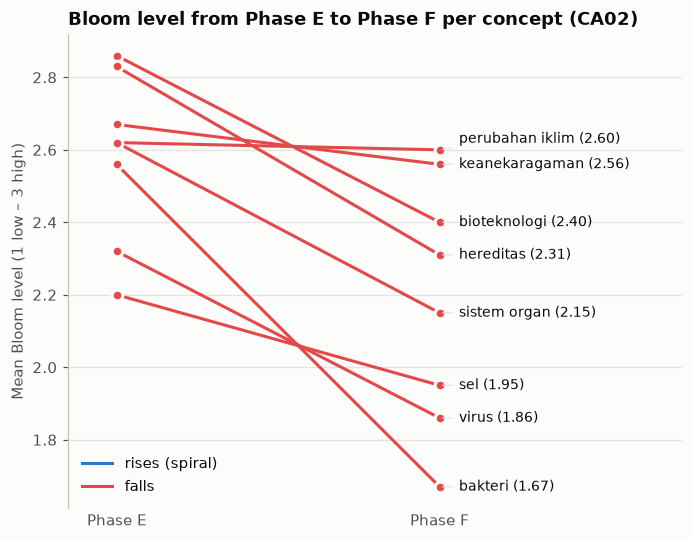

In [25]:
rows = [(cid.replace("_", " "), r["bloom_E"], r["bloom_F"]) for cid, r in ca["CA02"].items() if r.get("bloom_E") is not None]
fig, ax = plt.subplots(figsize=(7.2, 5.6))
if not rows:
    ax.text(0.5, 0.5, "No concept has enough Bloom data in both phases.", ha="center", va="center",
            color=VIZ["muted"], transform=ax.transAxes)
    ax.axis("off")
else:
    for name, e, f in rows:
        color = VIZ["blue"] if f > e else VIZ["red"] if f < e else VIZ["rule"]
        ax.plot([0, 1], [e, f], color=color, linewidth=2, marker="o", markersize=7, markeredgecolor=VIZ["surface"], markeredgewidth=2)
    # spread the right-hand labels so they do not overlap
    placed = []
    for name, e, f in sorted(rows, key=lambda r: r[2]):
        y_label = max(f, placed[-1] + 0.07) if placed else f
        placed.append(y_label)
        ax.annotate(f"{name} ({f:.2f})", xy=(1, f), xytext=(1.06, y_label), fontsize=9, va="center", color=VIZ["ink"],
                    arrowprops=dict(arrowstyle="-", color=VIZ["grid"], linewidth=0.8))
    ax.set_xticks([0, 1], ["Phase E", "Phase F"])
    ax.set_xlim(-0.15, 1.75)
    ax.set_ylabel("Mean Bloom level (1 low – 3 high)")
    ax.grid(axis="y", color=VIZ["grid"], linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines["bottom"].set_visible(False)
    ax.tick_params(axis="x", length=0)
    from matplotlib.lines import Line2D
    ax.legend([Line2D([0], [0], color=VIZ["blue"], lw=2), Line2D([0], [0], color=VIZ["red"], lw=2)],
              ["rises (spiral)", "falls"], loc="lower left", frameon=False)
ax.set_title("Bloom level from Phase E to Phase F per concept (CA02)")
save_fig(fig, "07_bloom_slope.png")

---
## 11. EN × CA integration

This section relates the EN labels (§8) to curriculum progression:

1. Does the proportion of each EN construct change from Phase E to Phase F? Of particular interest are Executive Function (EN03) and Metacognition (EN04), which are expected to increase with cognitive demand.
2. For each concept, how do EN03 and EN04 proportions in Phase E and Phase F relate to its spiral-progression status (CA02)?

Values are percentages of sentences labelled with the construct, over sentences assigned to a single phase.

In [26]:
def en_share(records):
    n = len(records)
    return {c: round(100 * sum(r[c] for r in records) / n, 2) if n else None for c in EN_COLS}

by_phase = {ph: [r for r in corpus if r["phase"] == ph] for ph in ("E", "F")}
phase_table = pd.DataFrame({ph: en_share(recs) for ph, recs in by_phase.items()})
phase_table["F - E"] = (phase_table["F"] - phase_table["E"]).round(2)
phase_table.insert(0, "name", [EN_NAMES[c] for c in EN_COLS])
print(f"EN proportion per phase (%) — n_E = {len(by_phase['E'])}, n_F = {len(by_phase['F'])}")
display(phase_table)

concept_rows = []
for cid, res in ca["CA02"].items():
    row = {"concept": cid, "CA02": res["CA02"]}
    for ph in ("E", "F"):
        recs = [corpus_by_id[o["sent_id"]] for o in concept_occurrences[cid] if o["phase"] == ph]
        share = en_share(recs)
        row[f"n_{ph}"] = len(recs)
        row[f"EN03_{ph}%"] = share["EN03"]
        row[f"EN04_{ph}%"] = share["EN04"]
    concept_rows.append(row)
concept_table = pd.DataFrame(concept_rows).set_index("concept")
print("EN03 / EN04 proportion per concept and phase (%)")
display(concept_table)

save_json({"en_by_phase": phase_table.drop(columns="name").to_dict(),
           "n_by_phase": {ph: len(v) for ph, v in by_phase.items()},
           "en03_en04_by_concept": concept_table.reset_index().to_dict("records")},
          os.path.join(FOLDER["results"], "integration_8EN_4CA.json"))
print(os.path.join(FOLDER["results"], "integration_8EN_4CA.json"))

EN proportion per phase (%) — n_E = 4480, n_F = 7201


,name,E,F,F - E
EN01,Attention,4.08,4.39,0.31
EN02,Learning & Memory,13.12,12.26,-0.86
EN03,Executive Function,1.88,0.82,-1.06
EN04,Metacognition,2.37,1.53,-0.84
EN05,Emotion/Affect,0.22,0.17,-0.05
EN06,Motivation/Agency,1.25,0.78,-0.47
EN07,Social Cognition,2.52,2.51,-0.01
EN08,Multimodal,1.12,0.47,-0.65


EN03 / EN04 proportion per concept and phase (%)


,CA02,n_E,EN03_E%,EN04_E%,n_F,EN03_F%,EN04_F%
concept,,,,,,,
gen,NaN,18,5.56,0.00,253,0.00,0.00
metabolisme,NaN,8,0.00,0.00,102,0.00,0.00
evolusi,NaN,13,0.00,0.00,211,1.42,1.42
bioteknologi,0.0,27,3.70,11.11,232,2.59,1.29
dna,NaN,17,0.00,0.00,263,0.76,0.00
protein,NaN,20,0.00,0.00,390,1.03,0.00
hereditas,0.0,18,5.56,11.11,145,2.07,0.69
fotosintesis,NaN,9,0.00,0.00,77,1.30,0.00
respirasi,NaN,1,0.00,0.00,40,0.00,0.00


results/integration_8EN_4CA.json


---
## 12. Alignment across curriculum layers

```
Intended curriculum     ->  CP
Designed curriculum     ->  Modul Ajar
Represented curriculum  ->  Buku Siswa (BS)
```

The three layers are compared on (1) the proportion of each EN construct, (2) coverage of Biology concepts, expressed as the percentage of the layer's sentences that mention the concept, and (3) cognitive demand: the share of sentences with a Bloom verb and their mean Bloom level.

In [27]:
by_layer = {dt: [r for r in corpus if r["document_type"] == dt] for dt in LAYERS}
layer_names = list(LAYERS.values())

en_layer = pd.DataFrame({LAYERS[dt]: en_share(recs) for dt, recs in by_layer.items()})
en_layer.insert(0, "name", [EN_NAMES[c] for c in EN_COLS])
print("EN proportion per layer (%) — " + ", ".join(f"{LAYERS[dt]}: n={len(v)}" for dt, v in by_layer.items()))
display(en_layer)

concept_layer = pd.DataFrame(
    {LAYERS[dt]: {cid: round(100 * sum(o["document_type"] == dt for o in occ) / len(by_layer[dt]), 2) if by_layer[dt] else None
                  for cid, occ in concept_occurrences.items()} for dt in LAYERS})
print("Concept coverage (% of the layer's sentences)")
display(concept_layer.sort_values(layer_names[-1], ascending=False))

bloom_layer = pd.DataFrame({LAYERS[dt]: {
    "% sentences with a Bloom verb": round(100 * np.mean([r["bloom"] > 0 for r in recs]), 1) if recs else None,
    "mean Bloom level of those sentences": round(float(np.mean([r["bloom"] for r in recs if r["bloom"] > 0])), 2) if any(r["bloom"] for r in recs) else None,
} for dt, recs in by_layer.items()})
print("Bloom")
display(bloom_layer)

save_json({"n_by_layer": {dt: len(v) for dt, v in by_layer.items()},
           "en_by_layer": en_layer.drop(columns="name").to_dict(),
           "concept_by_layer": concept_layer.to_dict(),
           "bloom_by_layer": bloom_layer.to_dict()},
          os.path.join(FOLDER["results"], "alignment_CP_module_textbook.json"))
print(os.path.join(FOLDER["results"], "alignment_CP_module_textbook.json"))

EN proportion per layer (%) — Intended (CP): n=52, Designed (Modul): n=462, Represented (Buku Siswa): n=9060


,name,Intended (CP),Designed (Modul),Represented (Buku Siswa)
EN01,Attention,3.85,3.46,4.62
EN02,Learning & Memory,26.92,17.32,9.35
EN03,Executive Function,7.69,1.95,0.39
EN04,Metacognition,7.69,4.76,0.68
EN05,Emotion/Affect,0.00,0.43,0.04
EN06,Motivation/Agency,3.85,1.52,0.13
EN07,Social Cognition,3.85,8.44,1.32
EN08,Multimodal,1.92,2.81,0.09


Concept coverage (% of the layer's sentences)


,Intended (CP),Designed (Modul),Represented (Buku Siswa)
sel,9.62,1.73,8.22
protein,0.00,3.46,3.92
virus,1.92,6.49,3.06
sistem_organ,11.54,11.26,2.98
gen,0.00,2.60,2.73
dna,0.00,3.90,2.47
bioteknologi,9.62,0.22,2.20
evolusi,9.62,7.36,1.83
kromosom,0.00,0.87,1.56
organel,1.92,0.22,1.36


Bloom


,Intended (CP),Designed (Modul),Represented (Buku Siswa)
% sentences with a Bloom verb,25.00,19.00,7.60
mean Bloom level of those sentences,2.77,2.26,2.15


results/alignment_CP_module_textbook.json


---
## 13. Labelling of held-out documents

Documents with `split = "predict"` were excluded from annotation and training. They are processed with the same extraction rules as the corpus and labelled with the tuned thresholds. New documents can be labelled without retraining by adding them to `DOCUMENTS` (§1) with `split = "predict"`.

Output: `results/prediksi_EN_dokumen_disisihkan.xlsx`, with one row per sentence (labels and probabilities) and a per-document summary sheet.

In [28]:
if "model" not in globals() or "TH" not in globals():
    model, TH = load_trained_model()

rows = []
for doc in PREDICT_DOCS:
    if not os.path.exists(doc["file"]):
        print(f"  [SKIP] {doc['document_id']}")
        continue
    ocr = needs_ocr(doc["file"])
    if ocr and not TESSERACT_OK:
        print(f"  [SKIP] {doc['document_id']} (OCR)")
        continue
    recs, _, _ = extract_sentences(doc, ocr=ocr)
    probs = predict_proba(model, [r["text"] for r in recs])
    for r, p in zip(recs, probs):
        row = {"sent_id": r["sent_id"], **{k: doc[k] for k in ["document_id", "document_type", "title", "phase", "grade", "chapter"]},
               "page": r["page"], "text": r["text"]}
        row.update({c: int(p[j] >= TH[j]) for j, c in enumerate(EN_COLS)})
        row.update({c + "_prob": round(float(p[j]), 3) for j, c in enumerate(EN_COLS)})
        rows.append(row)
    print(f"  {doc['document_id']:<14} {len(recs):>5} sentences" + (" (OCR)" if ocr else ""))

df_pred = pd.DataFrame(rows)
summary = (df_pred.groupby(["document_id", "document_type", "phase", "chapter"])
           .agg(n=("text", "size"), **{c: (c, "mean") for c in EN_COLS}).reset_index())
summary[EN_COLS] = (summary[EN_COLS] * 100).round(1)
print("Proportion of sentences per construct (%)")
display(summary)

path_xl = os.path.join(FOLDER["results"], "prediksi_EN_dokumen_disisihkan.xlsx")
wb = openpyxl.Workbook()
ws = wb.active; ws.title = "EN labels"
cols = list(df_pred.columns)
write_table(ws, cols, df_pred.values.tolist(), widths=[22, 16, 10, 30, 6, 7, 14, 6, 70] + [6] * 8 + [8] * 8,
            wrap={"text"}, freeze="J2", header_colors=EN_COLORS)
for r_i, row in enumerate(df_pred[EN_COLS].values, 2):
    for j, c in enumerate(EN_COLS):
        if row[j] == 1:
            cell = ws.cell(row=r_i, column=cols.index(c) + 1)
            cell.fill = PatternFill("solid", fgColor=EN_COLORS[c]); cell.font = Font(bold=True)
ws2 = wb.create_sheet("Summary")
write_table(ws2, [str(c) for c in summary.columns], summary.values.tolist(), widths=[18, 12, 7, 14, 7] + [9] * 8)
wb.save(path_xl)
print(path_xl)

  MOD_SEL          110 sentences
  MOD_GENETIKA      62 sentences
  MOD_TRANSPOR     186 sentences
  MOD_BAKTERI       65 sentences
  MOD_ZW2          193 sentences
Proportion of sentences per construct (%)


,document_id,document_type,phase,chapter,n,EN01,EN02,EN03,EN04,EN05,EN06,EN07,EN08
0,MOD_BAKTERI,module,E,Bakteri,65,21.5,40.0,1.5,1.5,0.0,1.5,18.5,12.3
1,MOD_GENETIKA,module,F,Genetika,62,11.3,25.8,1.6,3.2,0.0,0.0,16.1,4.8
2,MOD_SEL,module,F,Sel,110,6.4,23.6,0.9,2.7,0.0,0.9,10.9,0.9
3,MOD_TRANSPOR,module,F,Sel,186,3.8,16.7,0.0,1.1,0.0,0.5,3.8,1.6
4,MOD_ZW2,module,E,Lingkungan,193,5.2,20.2,1.6,4.1,0.0,1.0,4.1,1.0


results/prediksi_EN_dokumen_disisihkan.xlsx


---
## Limitations

- **Annotation reliability.** Inter-annotator agreement reached a mean κ of 0.86, and every construct is above the planned 0.70; the lowest κ is EN07 (0.77) (§5).
- **Classifier performance.** Test macro-F1 is 0.39 (§7) and cross-validated macro-F1 0.54–0.58 (§7b). The test set holds only 138 sentences, so per-construct F1 is very uncertain; EN05 and EN08 have only two positives in it. The learning curve is still rising: more consistently labelled data would most likely raise F1. The EN labels and every analysis built on them (§8–§13) are therefore exploratory.
- **Weak constructs.** EN05 (14 positives) and EN08 (15 positives) have fewer than 20 positive examples. Their predicted proportions should not be interpreted.
- **Predicted proportions.** The percentages in §8, §11, §12, and §13 are model outputs with limited precision and recall, not human counts.
- **Text-only evidence.** EN08 (Multimodal) captures linguistic references to pictures, videos, or models, not the multimodal material itself.
- **Extraction.** PDF lines shorter than three words are removed, which can drop the end of a sentence that wraps onto a new line. CP documents are read with OCR and may contain recognition errors.
- **Heuristic measures.** Concept detection relies on synonym lists and Bloom levels on action-verb lists. Both are transparent but do not resolve word sense (e.g., *jaringan* as tissue vs. network). Only concepts with at least five Bloom-bearing sentences in both phases receive a CA02 status.